In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
customers = pd.read_csv('/content/drive/MyDrive/New Folder/Customers (2).csv')
orders = pd.read_csv('/content/drive/MyDrive/New Folder/Orders (1).csv')
products = pd.read_csv('/content/drive/MyDrive/New Folder/Products (1).csv')
order_items = pd.read_csv('/content/drive/MyDrive/New Folder/Order_Items (1).csv')
returns = pd.read_csv('/content/drive/MyDrive/New Folder/Returns.csv')
payment = pd.read_csv('/content/drive/MyDrive/New Folder/Payments (1).csv')

#Cleaning Customers Table

In [ ]:
customers.head()

,Customer_ID,Customer_Name,Age,Gender,City,State,Phone,Acquisition_Channel,Customer_Segment,Signup_Date
0,100001,Daniel Thomas,34.0,Female,Kaduna,Kaduna,08030853448,Google,Returning,2023-04-28
1,100002,John Musa,28.0,Male,Ilorin,Kwara,08041279947,Facebook,Returning,2024-06-30
2,100003,Esther Ogunleye,42.0,Female,Benin City,Edo,08087478915,Email,Loyal,2023-05-10
3,100004,Daniel Udo,49.0,Female,Lagos,Lagos,08019252651,Facebook,New,2025-10-21
4,100005,Chioma Adeyemi,30.0,Female,Abuja,FCT,08019770000,Instagram,New,2025-12-10


In [ ]:
 for col in customers.columns:
  print(col)
  print(customers[col].unique())
  print()

Customer_ID
[100001 100002 100003 ... 104998 104999 105000]

Customer_Name
['Daniel Thomas' 'John Musa' 'Esther Ogunleye' 'Daniel Udo'
 'Chioma Adeyemi' 'Mary Sani' 'Blessing Thomas' 'Mary Williams'
 'Sarah Balogun' 'Mary Eze' 'Michael Brown' 'Yusuf Lawal' 'Esther Nwosu'
 'Mary Musa' 'Samuel Johnson' 'Daniel Smith' 'Emeka Adeyemi' 'Emeka Nwosu'
 'Tunde Lawal' 'Michael Thomas' 'Blessing Eze' 'Daniel Sani' 'John Thomas'
 'Yusuf Ibrahim' 'David Balogun' 'Samuel Okafor' 'Mary Ibrahim'
 'Blessing Udo' 'Ruth Bello' 'David Sani' 'Esther Adebayo' 'Ruth Eze'
 'Daniel Balogun' 'Samuel Williams' 'John Balogun' 'Fatima Johnson'
 'Ibrahim Udo' 'Ruth Musa' 'Michael Nwosu' 'Ada Bello' 'Daniel Adebayo'
 'Yusuf Nwosu' 'Sarah Eze' 'Emeka Oyekola' 'Chioma Udo' 'Ada Williams'
 'Sarah Ibrahim' 'Sarah Okafor' 'Yusuf Thomas' 'Yusuf Udo' 'Samuel Bello'
 'Tunde Thomas' 'Ibrahim Balogun' 'Mary Smith' 'Aisha Williams'
 'Chioma Williams' 'Esther Udo' 'Emeka Smith' 'Ibrahim Lawal'
 'Ibrahim Smith' 'Yusuf Adebayo' 

In [ ]:
customers.describe()

,Customer_ID,Age
count,5040.000000,5009.000000
mean,102503.890675,41.326812
std,1442.836721,13.814234
min,100001.000000,18.000000
25%,101254.750000,30.000000
50%,102506.500000,41.000000
75%,103750.250000,53.000000
max,105000.000000,65.000000


In [ ]:
customers.duplicated().sum()
customers.drop_duplicates(inplace=True)

In [ ]:
customers['Customer_Name'].isna().sum()

np.int64(30)

In [ ]:
#Replacing nan customer name with unknown
customers['Customer_Name'].fillna('Unknown', inplace=True)

/tmp/ipykernel_648/2542267706.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  customers['Customer_Name'].fillna('Unknown', inplace=True)


<Axes: >

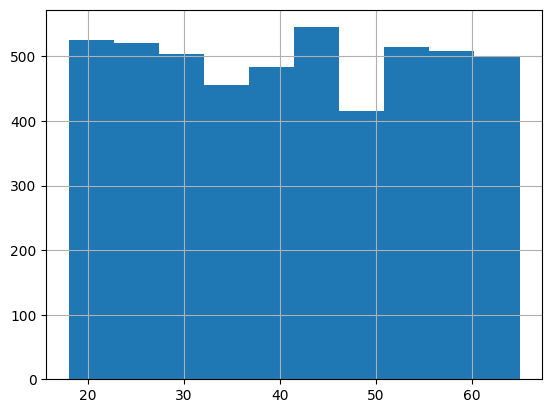

In [ ]:
#Unique Age and changing the datatype fron float to int
#No outliers in the age column
customers['Age'].unique()
customers['Age'].hist()


In [ ]:
#Filling the null age with the median age
customers['Age'] = customers['Age'].fillna(customers['Age'].median())

In [ ]:
customers['Age'] = customers['Age'].astype('int64')

In [ ]:
#Cleaning the state column
customers['State'].str.strip()
customers['State'].unique()

array(['Kaduna', 'Kwara', 'Edo', 'Lagos', 'FCT', 'Oyo', 'Ogun', 'Kano',
       'Rivers', 'Enugu'], dtype=object)

In [ ]:
#Replacing the incorrect values in the city column
customers['City'] = customers['City'].replace('Port Harcourt ', 'Port Harcourt')
customers['City'] =  customers['City'].replace('lagos', 'Lagos')
customers['City'] =  customers['City'].replace('LAGOS', 'Lagos')
customers['City'] =  customers['City'].replace('Lagos ', 'Lagos')
customers['City'] =  customers['City'].replace(' lagos', 'Lagos')
customers['City'] =  customers['City'].replace('Abujaa', 'Abuja')
customers['City'] =  customers['City'].replace('Ibaddan', 'Ibadan')

In [ ]:
#Cleaing the city column and checking for null values
customers['City'].str.strip()
customers['City'].isna().sum()
customers['City'].unique()

array(['Kaduna', 'Ilorin', 'Benin City', 'Lagos', 'Abuja', 'Ibadan',
       'Abeokuta', 'Kano', 'Port Harcourt', 'Enugu'], dtype=object)

In [ ]:
#Replacing misspelled or incorrect values
customers['Gender'] = customers['Gender'].replace('M', 'Male')
customers['Gender'] = customers['Gender'].replace('F', 'Female')
customers['Gender'] = customers['Gender'].replace('FEMALE ', 'Female')
customers['Gender'] = customers['Gender'].replace('female', 'Female')
customers['Gender'] = customers['Gender'].replace('Male ', 'Male')

In [ ]:
customers['Gender'].str.strip()
customers['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [ ]:
#Replacing incorrect values
customers['Acquisition_Channel'] = customers['Acquisition_Channel'].replace('instagram', 'Instagram')
customers['Acquisition_Channel'] = customers['Acquisition_Channel'].replace('Instagram ', 'Instagram')
customers['Acquisition_Channel'] = customers['Acquisition_Channel'].fillna('Unknown')

In [ ]:
#Acquisition channel
customers['Acquisition_Channel'].str.title()
customers['Acquisition_Channel'].str.strip()
customers['Acquisition_Channel'].unique()
customers['Acquisition_Channel'].isna().sum()

np.int64(0)

In [ ]:
#Replacing inconsistent values
customers['Customer_Segment'] = customers['Customer_Segment'].replace('vip', 'VIP')
customers['Customer_Segment'] = customers['Customer_Segment'].replace('Loyal ', 'Loyal')
customers['Customer_Segment'] = customers['Customer_Segment'].fillna('Unknown')

In [ ]:
#Customer Segment
customers['Customer_Segment'].str.title()
customers['Customer_Segment'].str.strip()
customers['Customer_Segment'].unique()

array(['Returning', 'Loyal', 'New', 'VIP', 'Regular', 'Unknown'],
      dtype=object)

In [ ]:
customers['Signup_Date'].unique()
customers['Signup_Date'].value_counts()

,count
Signup_Date,
2024-04-08,13
2024-06-01,12
2024-11-05,11
2023-03-30,11
2023-05-05,11
...,...
2025-11-29,1
2024-06-29,1
2024-02-15,1


In [ ]:
# Changing Signup date datatype
customers['Signup_Date'] = pd.to_datetime(customers['Signup_Date'])

In [ ]:
import re

# 1. Define the formatting logic for Nigerian numbers
def clean_nigerian_phone(phone):
    if pd.isna(phone):
        return None

    # Strip all symbols like dashes (-), spaces, or plus signs (+), keeping only digits
    digits = re.sub(r'\D', '', str(phone))

    # Format standard international entries (e.g., 2348012345678 -> +2348012345678)
    if digits.startswith('234') and len(digits) == 13:
        return f"+{digits}"

    # Format local entries and numbers with dashes (e.g., 080-1234-5678 -> +2348012345678)
    if digits.startswith('0') and len(digits) == 11:
        return f"+234{digits[1:]}"

    # Mark incomplete entries (like '08012345') as None so they can be dropped or filtered
    return None

# 2. Update the 'Phone' column in your 'customers' DataFrame instantly
customers['Phone'] = customers['Phone'].apply(clean_nigerian_phone)

# 3. See a quick sample of your updated data
print(customers['Phone'].head(10))


0    +2348030853448
1    +2348041279947
2    +2348087478915
3    +2348019252651
4    +2348019770000
5    +2348037186161
6    +2348082603570
7    +2348060631139
8    +2348054413157
9    +2348088385196
Name: Phone, dtype: object


In [ ]:
customers['Phone'].isna().sum()

np.int64(13)

In [ ]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Customer_ID          5000 non-null   int64         
 1   Customer_Name        5000 non-null   object        
 2   Age                  5000 non-null   int64         
 3   Gender               5000 non-null   object        
 4   City                 5000 non-null   object        
 5   State                5000 non-null   object        
 6   Phone                4987 non-null   object        
 7   Acquisition_Channel  5000 non-null   object        
 8   Customer_Segment     5000 non-null   object        
 9   Signup_Date          5000 non-null   datetime64[ns]
dtypes: datetime64[ns](1), int64(2), object(7)
memory usage: 429.7+ KB


In [ ]:
print(customers.shape)

(5000, 10)


#Cleaning Orders Table

In [ ]:
#Deleting duplicates
orders.duplicated().sum()
orders.drop_duplicates(inplace=True)

In [ ]:
orders.describe()

,Order_ID,Customer_ID,Shipping_Fee,Discount
count,20000.000000,20000.000000,20000.000000,20000.000000
mean,510000.500000,104765.050050,1536.375000,1223.948800
std,5773.647028,44782.403696,1609.042824,3619.221501
min,500001.000000,-1.000000,-1000.000000,-1000.000000
25%,505000.750000,101259.000000,1000.000000,0.000000
50%,510000.500000,102507.500000,1500.000000,1000.000000
75%,515000.250000,103772.000000,2000.000000,1500.000000
max,520000.000000,999999.000000,50000.000000,99999.000000


In [ ]:
for col in orders.columns:
  print(col)
  print(orders[col].unique())
  print()

Order_ID
[500001 500002 500003 ... 519998 519999 520000]

Customer_ID
[100341 104393 102966 ... 101879 100929 100931]

Order_Date
['2024-11-07' '2024-01-16' '2024-08-05' '2024-10-15' '2025-04-23'
 '2025-03-16' '2024-09-28' '2025-03-28' '2025-10-13' '2024-09-12'
 '2024-09-30' '2024-03-15' '2024-10-03' '2024-07-26' '2025-07-08'
 '2024-03-23' '2025-03-07' '2025-07-18' '2024-07-05' '2024-02-19'
 '2025-05-09' '2025-03-06' '2025-02-15' '2025-10-05' '2024-03-17'
 '2024-05-24' '2024-12-07' '2025-02-14' '2025-11-02' '2024-06-03'
 '2025-09-14' '2024-10-30' '2025-09-26' '2024-07-20' '2025-08-01'
 '2025-01-27' '2025-02-10' '2025-12-13' '2024-04-22' '2024-08-14'
 '2024-05-13' '2025-08-31' '2025-09-13' '2025-09-04' '2024-06-23'
 '2024-07-08' '2024-10-20' '2025-07-03' '2025-12-23' '2025-07-27'
 '2025-11-28' '2024-07-13' '2025-03-18' '2025-01-24' '2024-04-20'
 '2025-11-23' '2024-03-28' '2025-09-16' '2024-07-14' '2024-06-10'
 '2025-03-15' '2024-10-09' '2025-10-22' '2025-05-25' '2025-03-21'
 '2025-07-29

In [ ]:
#Replacing null and inconsistent values in order date
orders['Order_Date'] = orders['Order_Date'].replace('March 5 2025', '2025-03-05')
orders['Order_Date'] = orders['Order_Date'].replace('2024/03/17', '2024-03-17')
orders['Order_Date'] = orders['Order_Date'].replace('17-04-2024', '2024-04-17')
orders['Order_Date'] = orders['Order_Date'].replace('12/11/2024', '2024-11-12')
orders['Order_Date'] = orders['Order_Date'].replace('01/02/2024', '2024-02-01')
orders['Order_Date'] = orders['Order_Date'].replace('unknown', 'nan')
orders['Order_Date'] = orders['Order_Date'].fillna('nan')


In [ ]:
#Changing order date datatype
orders['Order_Date'] = pd.to_datetime(orders['Order_Date'], format='mixed')

In [ ]:
orders['Order_Status'].str.strip()
orders['Order_Status'].str.title()

,Order_Status
0,Delivered
1,Delivered
2,Delivered
3,Returned
4,Delivered
...,...
19995,Processing
19996,Delivered
19997,Delivered
19998,Delivered


In [ ]:
#Checking order status
orders['Order_Status'].unique()

array(['Delivered', 'Returned', 'Processing', 'Cancelled', 'delivered',
       'cancelled ', 'Complete', 'DELIVERED'], dtype=object)

In [ ]:
orders['Order_Status'] = orders['Order_Status'].replace('delivered', 'Delivered')
orders['Order_Status'] = orders['Order_Status'].replace('cancelled ', 'Cancelled')
orders['Order_Status'] = orders['Order_Status'].replace('DELIVERED', 'Delivered')
orders['Order_Status'] = orders['Order_Status'].replace('Complete', 'Delivered')

In [ ]:
#Cleaning Payment method column
orders['Payment_Method'].str.strip()
orders['Payment_Method'].str.title()

,Payment_Method
0,Ussd
1,Cash On Delivery
2,Card
3,Card
4,Bank Transfer
...,...
19995,Paypal
19996,Cash On Delivery
19997,Cash On Delivery
19998,Bank Transfer


In [ ]:
orders['Payment_Method'].unique()

array(['USSD', 'Cash on Delivery', 'Card', 'Bank Transfer', 'PayPal',
       'Bank transfer', 'bank_transfer', 'CARD', 'card', nan, 'Cash'],
      dtype=object)

In [ ]:
#Replacing inconsistent values
orders['Payment_Method'] = orders['Payment_Method'].replace('Cash', 'Cash on Delivery')
orders['Payment_Method'] = orders['Payment_Method'].replace('Bank transfer', 'Bank Transfer')
orders['Payment_Method'] = orders['Payment_Method'].replace('bank_transfer', 'Bank Transfer')
orders['Payment_Method'] = orders['Payment_Method'].replace('CARD', 'Card')
orders['Payment_Method'] = orders['Payment_Method'].replace('card', 'Card')
orders['Payment_Method'] = orders['Payment_Method'].fillna('Unknown')

In [ ]:
#Shipping City
orders['Shipping_City'].str.strip()
orders['Shipping_City'].str.title()
orders['Shipping_City'].unique()

array(['Kano', 'Port Harcourt', 'Lagos', 'Abuja', 'Abeokuta', 'Kaduna',
       'Benin City', 'Ibadan', 'Enugu', 'Ilorin', 'Abujaa',
       'Port Harcourt ', 'Ibaddan', 'Lagos ', ' lagos'], dtype=object)

In [ ]:
#Replacing values
orders['Shipping_City'] = orders['Shipping_City'].replace('Abujaa', 'Abuja')
orders['Shipping_City'] = orders['Shipping_City'].replace('Port Harcourt ', 'Port Harcourt')
orders['Shipping_City'] = orders['Shipping_City'].replace(' lagos', 'Lagos')
orders['Shipping_City'] = orders['Shipping_City'].replace('Lagos ', 'Lagos')
orders['Shipping_City'] = orders['Shipping_City'].replace('Ibaddan', 'Ibadan')


In [ ]:
#Replacing the negative values as they are inconsistent with the business rule and affected the records
orders['Shipping_Fee'] = orders['Shipping_Fee'].replace(-500,500)
orders['Shipping_Fee'] = orders['Shipping_Fee'].replace(-1000,1000)
orders['Shipping_Fee'].unique()
#Outlier of 99999 noticed but will be investgated later when I merge all teh tables together

array([ 1500,     0,  1000,  3000,  2500,  2000, 50000,   500])

In [ ]:
#Replacing the negative values as they are inconsistent with the business rule and affected the records
orders['Discount'] = orders['Discount'].replace(-1000,1000)
orders['Discount'] = orders['Discount'].replace(-500,500)
orders['Discount'].unique()
#Outlier of 99999 noticed but will be investgated later when I merge all the tables together

array([  500,  1000,  1500,  2000,     0,  5000,  3000, 99999])

In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20000 entries, 0 to 19999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        20000 non-null  int64         
 1   Customer_ID     20000 non-null  int64         
 2   Order_Date      19950 non-null  datetime64[ns]
 3   Order_Status    20000 non-null  object        
 4   Payment_Method  20000 non-null  object        
 5   Shipping_City   20000 non-null  object        
 6   Shipping_Fee    20000 non-null  int64         
 7   Discount        20000 non-null  int64         
dtypes: datetime64[ns](1), int64(4), object(3)
memory usage: 1.4+ MB


#Cleaning Order items table

In [ ]:
order_items.head()

,Order_Item_ID,Order_ID,Product_ID,Quantity,Unit_Price,Line_Total
0,800001,513888,2091,1.0,24119.73,24119.73
1,800002,519353,2056,1.0,12379.24,12379.24
2,800003,517892,2085,3.0,42539.50,127618.50
3,800004,504714,2017,4.0,18356.63,73426.52
4,800005,519344,2098,1.0,44022.34,44022.34


In [ ]:
for col in order_items.columns:
  print(col)
  print(order_items[col].unique())
  print()

Order_Item_ID
[800001 800002 800003 ... 834998 834999 835000]

Order_ID
[513888 519353 517892 ... 503193 501970 519337]

Product_ID
[2091 2056 2085 2017 2098 2052 2029 2055 2015 2023 2005 2054 2059 2096
 2083 2074 2063   -5 2038 2050 2073 2031 2075 2090 2078 2049 2080 2058
 2002 2036 2019 2060 2076 2011 2016 2093 2095 2009 2084 2061 2072 2034
 2028 2069 2099 2004 2039 2088 2057 2043 2003 2097 2100 2047 2032 2064
 2013 2048 2094 2030 2024 2041 2042 2014 2068 2044 2071 2065 2035 2007
 2079 2025 2037 2040 2020 2021 2026 2001 2018 2092 2006 2082 2008 2012
 2077 2033 2062 2022 2070 2053 2081 2086 2089 2045 2087 2046 2051 2066
 2067 2027 2010 9999]

Quantity
[ 1.  3.  4.  5. 99.  6.  2. nan -1. -2.  0.]

Unit_Price
[24119.73 12379.24 42539.5  ... 20688.66 29485.3  36201.82]

Line_Total
[ 24119.73  12379.24 127618.5  ...  41377.32  58970.6   36201.82]



In [ ]:
#Checking fro duplicates and deleting duplicates
order_items.duplicated().sum()
order_items.drop_duplicates(inplace=True)

In [ ]:
#Checking Quantity: replacing values and outliers
order_items['Quantity'] = order_items['Quantity'].replace(-1, 1)
order_items['Quantity'] = order_items['Quantity'].replace(-2, 2)
order_items['Quantity'].unique()

array([ 1.,  3.,  4.,  5., 99.,  6.,  2., nan,  0.])

In [ ]:
#Replacing outliers in product_id
order_items['Quantity'] = order_items['Quantity'].replace(99, 10)

In [ ]:
order_items['Quantity'].value_counts()

,count
Quantity,
1.0,5919
2.0,5883
3.0,5850
6.0,5819
4.0,5775
5.0,5677
10.0,18
0.0,9


In [ ]:
del order_items['Line_Total']

In [ ]:
#Create another line total column to be sure its correct
order_items['Line_Total'] = order_items['Quantity'] * order_items['Unit_Price']

In [ ]:
order_items['Unit_Price'].unique()

array([24119.73, 12379.24, 42539.5 , ..., 20688.66, 29485.3 , 36201.82])

In [ ]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
Index: 35000 entries, 0 to 34999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_Item_ID  35000 non-null  int64  
 1   Order_ID       35000 non-null  int64  
 2   Product_ID     35000 non-null  int64  
 3   Quantity       34950 non-null  float64
 4   Unit_Price     35000 non-null  float64
 5   Line_Total     34950 non-null  float64
dtypes: float64(3), int64(3)
memory usage: 1.9 MB


In [ ]:
#Creat revenue analysis table by merging customers table, orders table and order items table
Revenue_analysis = customers.merge(orders, on='Customer_ID', how='inner').merge(order_items, on='Order_ID', how='inner')
Revenue_analysis.head()

,Customer_ID,Customer_Name,Age,Gender,City,State,Phone,Acquisition_Channel,Customer_Segment,Signup_Date,...,Order_Status,Payment_Method,Shipping_City,Shipping_Fee,Discount,Order_Item_ID,Product_ID,Quantity,Unit_Price,Line_Total
0,100001,Daniel Thomas,34,Female,Kaduna,Kaduna,+2348030853448,Google,Returning,2023-04-28,...,Delivered,Card,Abeokuta,2000,0,806183,2077,3.0,6739.40,20218.20
1,100001,Daniel Thomas,34,Female,Kaduna,Kaduna,+2348030853448,Google,Returning,2023-04-28,...,Delivered,Card,Abeokuta,2000,0,817267,2035,6.0,36129.63,216777.78
2,100002,John Musa,28,Male,Ilorin,Kwara,+2348041279947,Facebook,Returning,2024-06-30,...,Delivered,Cash on Delivery,Benin City,2500,2000,816589,2036,4.0,40062.66,160250.64
3,100002,John Musa,28,Male,Ilorin,Kwara,+2348041279947,Facebook,Returning,2024-06-30,...,Delivered,Cash on Delivery,Benin City,2500,2000,818362,2064,1.0,16093.01,16093.01
4,100002,John Musa,28,Male,Ilorin,Kwara,+2348041279947,Facebook,Returning,2024-06-30,...,Delivered,Cash on Delivery,Benin City,2500,2000,820707,2028,2.0,34963.49,69926.98


#Cleaning Product Table

In [ ]:
products.head()

,Product_ID,Product_Name,Category,Unit_Price,Cost_Price,Supplier,Stock_Level
0,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.2540,PureCare,384
1,2002,Cleansing Oil 2,Skincare,19339.11,16438.2435,BeautyMart,198
2,2003,Niacinamide Serum 3,Accessories,21540.24,15206.4000,PureCare,163
3,2004,Body Lotion 4,Skincare,18504.74,15729.0290,DermaSupply,402
4,2005,Sunscreen SPF 50 5,Skincare,23866.63,2157.6400,GlowHub,177


In [ ]:
products.duplicated().sum()
products.drop_duplicates(inplace=True)

In [ ]:
# The settings will revert back to default once outside this block
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    print(products)


    Product_ID                Product_Name      Category  Unit_Price  \
0         2001   Brightening Moisturizer 1      Skincare     9473.24   
1         2002             Cleansing Oil 2      Skincare    19339.11   
2         2003         Niacinamide Serum 3   Accessories    21540.24   
3         2004               Body Lotion 4      Skincare    18504.74   
4         2005          Sunscreen SPF 50 5      Skincare    23866.63   
5         2006     Hyaluronic Acid Serum 6      Skincare    33675.81   
6         2007          Eye Repair Cream 7      Skincare    29517.43   
7         2008         Exfoliating Toner 8      Bodycare    28479.63   
8         2009          Eye Repair Cream 9      Bodycare    26205.60   
9         2010     Hydrating Face Cream 10      Skincare    11039.45   
10        2011         Sunscreen SPF 50 11      Skincare    28197.05   
11        2012             Tea Tree Gel 12      Haircare     9234.38   
12        2013         Eye Repair Cream 13      Skincare    3279

In [ ]:
Price = products['Cost_Price'] > products['Unit_Price']
print(Price.sum())

0


In [ ]:
products['Product_Name'].str.strip()
products['Product_Name'].str.title()
products['Product_Name'].unique()

array(['Brightening Moisturizer 1', 'Cleansing Oil 2',
       'Niacinamide Serum 3', 'Body Lotion 4', 'Sunscreen SPF 50 5',
       'Hyaluronic Acid Serum 6', 'Eye Repair Cream 7',
       'Exfoliating Toner 8', 'Eye Repair Cream 9',
       'Hydrating Face Cream 10', 'Sunscreen SPF 50 11',
       'Tea Tree Gel 12', 'Eye Repair Cream 13', 'Tea Tree Gel 14',
       'Brightening Moisturizer 15', 'Retinol Night Cream 16',
       'Niacinamide Serum 17', 'Sunscreen SPF 50 18', 'Lip Balm 19',
       'Niacinamide Serum 20', 'Retinol Night Cream 21',
       'Gentle  Cleanser  22', 'Retinol Night Cream 23',
       'Brightening Moisturizer 24', 'Hyaluronic Acid Serum 25',
       'Body Lotion 26', 'Hyaluronic Acid Serum 27',
       'Hyaluronic Acid Serum 28', 'Eye Repair Cream 29',
       'Hydrating Face Cream 30', 'Retinol Night Cream 31',
       'Gentle Cleanser 32', 'Gentle Cleanser 33', 'Clay Face Mask 34',
       'Gentle Cleanser 35', 'Niacinamide Serum 36', 'Lip Balm 37',
       'Retinol Night

In [ ]:
products['Category'].str.strip()
products['Category'].str.title()
products['Category'].unique()

array(['Skincare', 'Accessories', 'Bodycare', 'Haircare', 'SKINCARE',
       'skin care', 'Body Care', 'Accessories ', 'Hair care'],
      dtype=object)

In [ ]:
products['Category'] = products['Category'].replace('SKINCARE', 'Skincare')
products['Category'] = products['Category'].replace('skin care', 'Skincare')
products['Category'] = products['Category'].replace('Body Care', 'Bodycare')
products['Category'] = products['Category'].replace('Accessories ', 'Accessories')
products['Category'] = products['Category'].replace('Hair care', 'Haircare')

In [ ]:
#Cleaning and replacing supplier column
products['Supplier'].str.strip()
products['Supplier'].str.title()
products['Supplier'].unique()

array(['PureCare', 'BeautyMart', 'DermaSupply', 'GlowHub', 'SkinSource',
       'glowhub', 'Glow Hub', 'Pure Care', 'Beauty Mart', 'Unknown'],
      dtype=object)

In [ ]:
products['Supplier'] = products['Supplier'].replace('glowhub', 'GlowHub')
products['Supplier'] = products['Supplier'].replace('Glow Hub', 'GlowHub')
products['Supplier'] = products['Supplier'].replace('Pure Care', 'PureCare')
products['Supplier'] = products['Supplier'].replace('Beauty Mart', 'BeautyMart')

In [ ]:
#Stock level column
products['Stock_Level'].unique()

array([ 384,  198,  163,  402,  177,   65,  397,  158,  327,  329,   41,
         16,  410,   27,  165,  381,   88,  261,   57,  278,  356,  124,
        140,  265,  395,  272,  350,  206,   64,  482,  398,   24,  137,
        207,   40,  428,   86,  103,  467,  112,  212,  341,   78,   44,
         46,   91,  470,  459,    2,  469,   14,  281,  222,   59,  276,
        228,  208,    5,  115,  236,   38,   10,    1,  136,  185,  445,
        351,  426,  197,  196,    6,  486,  343, 9999,  330,  496,   80,
        372,  433,  293,  331,  253,   77,  490,  143,  192,   28,  203,
        277,  118,  335,  262,  131,  102])

In [ ]:
#Replacing outliers
products['Stock_Level'] = products['Stock_Level'].replace(9999, 200)
products['Stock_Level'] = products['Stock_Level'].replace(-2, 2)

In [ ]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Product_ID    100 non-null    int64  
 1   Product_Name  100 non-null    object 
 2   Category      100 non-null    object 
 3   Unit_Price    100 non-null    float64
 4   Cost_Price    100 non-null    float64
 5   Supplier      100 non-null    object 
 6   Stock_Level   100 non-null    int64  
dtypes: float64(2), int64(2), object(3)
memory usage: 5.6+ KB


In [ ]:
#Creating product performance table
Product_p = products.merge(order_items, on='Product_ID', how='inner').merge(orders, on='Order_ID', how='inner')
Product_p

,Product_ID,Product_Name,Category,Unit_Price_x,Cost_Price,Supplier,Stock_Level,Order_Item_ID,Order_ID,Quantity,Unit_Price_y,Line_Total,Customer_ID,Order_Date,Order_Status,Payment_Method,Shipping_City,Shipping_Fee,Discount
0,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800166,500286,4.0,9473.24,37892.96,103406,2025-12-16,Delivered,Bank Transfer,Ilorin,2500,1500
1,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800199,507343,5.0,9473.24,47366.20,103987,2024-06-09,Processing,Cash on Delivery,Lagos,2000,0
2,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800231,509760,2.0,9473.24,18946.48,103823,2025-09-11,Delivered,Card,Enugu,1500,2000
3,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800261,515493,2.0,9473.24,18946.48,101106,2024-05-29,Delivered,Card,Enugu,1500,0
4,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800390,502127,3.0,9473.24,28419.72,102065,2024-09-19,Delivered,Card,Abeokuta,1500,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34865,2100,Gentle Cleanser 100,Skincare,32216.53,13838.890,DermaSupply,102,834690,501287,6.0,32216.53,193299.18,103992,2024-08-08,Delivered,Bank Transfer,Benin City,1500,1500
34866,2100,Gentle Cleanser 100,Skincare,32216.53,13838.890,DermaSupply,102,834801,511139,3.0,32216.53,96649.59,101103,2024-09-17,Cancelled,Card,Kaduna,1500,500
34867,2100,Gentle Cleanser 100,Skincare,32216.53,13838.890,DermaSupply,102,834867,511309,5.0,32216.53,161082.65,103758,2024-05-19,Delivered,Bank Transfer,Abeokuta,2500,1000
34868,2100,Gentle Cleanser 100,Skincare,32216.53,13838.890,DermaSupply,102,834973,512793,6.0,32216.53,193299.18,100074,2024-03-05,Delivered,Bank Transfer,Benin City,2500,1000


#Cleaning Payment Table

In [ ]:
payment.head()

,Payment_ID,Order_ID,Payment_Date,Amount_Paid,Payment_Status
0,900001,509845,24/03/2024,105081.47,Pending
1,900002,500997,30/07/2025,76221.43,Successful
2,900003,509891,04/01/2025,7808.08,Successful
3,900004,510468,06/10/2025,132361.31,Successful
4,900005,515134,09/01/2025,44998.50,Successful


In [ ]:
payment.duplicated().sum()
payment.drop_duplicates(inplace=True)

In [ ]:
for col in payment.columns:
  print(col)
  print(payment[col].unique())
  print()

Payment_ID
[900001 900002 900003 ... 918498 918499 918500]

Order_ID
[509845 500997 509891 ... 517718 507081 504513]

Payment_Date
['24/03/2024' '30/07/2025' '04/01/2025' '06/10/2025' '09/01/2025'
 '11/07/2024' '19/02/2025' '02/03/2025' '13/01/2025' '06/09/2025'
 '08/08/2025' '08/01/2024' '19/10/2025' '26/05/2024' '29/12/2024'
 '03/11/2024' '20/10/2024' '18/12/2025' '16/02/2024' '14/03/2024'
 '22/09/2025' '30/11/2025' '03/07/2025' '27/03/2024' '24/12/2025'
 '12/06/2025' '24/07/2025' '31/03/2024' '02/06/2024' '28/03/2024'
 '18/04/2025' '06/07/2024' '20/01/2025' '29/08/2025' '27/05/2024'
 '28/11/2024' '26/04/2024' '08/04/2025' '29/05/2025' '03/05/2024'
 '27/06/2025' '08/12/2024' '21/04/2024' '17/09/2025' '31/10/2024'
 '31/10/2025' '20/09/2025' '26/08/2024' '14/11/2025' '29/06/2024'
 '05/07/2025' '03/08/2024' '14/12/2024' '14/12/2025' '04/02/2024'
 '02/05/2024' '10/01/2025' '01/12/2025' '05/09/2025' '14/06/2025'
 '02/10/2024' '17/04/2024' '03/09/2024' '17/03/2025' '30/09/2024'
 '04/12/202

In [ ]:
payment['Payment_Date'].unique()

array(['24/03/2024', '30/07/2025', '04/01/2025', '06/10/2025',
       '09/01/2025', '11/07/2024', '19/02/2025', '02/03/2025',
       '13/01/2025', '06/09/2025', '08/08/2025', '08/01/2024',
       '19/10/2025', '26/05/2024', '29/12/2024', '03/11/2024',
       '20/10/2024', '18/12/2025', '16/02/2024', '14/03/2024',
       '22/09/2025', '30/11/2025', '03/07/2025', '27/03/2024',
       '24/12/2025', '12/06/2025', '24/07/2025', '31/03/2024',
       '02/06/2024', '28/03/2024', '18/04/2025', '06/07/2024',
       '20/01/2025', '29/08/2025', '27/05/2024', '28/11/2024',
       '26/04/2024', '08/04/2025', '29/05/2025', '03/05/2024',
       '27/06/2025', '08/12/2024', '21/04/2024', '17/09/2025',
       '31/10/2024', '31/10/2025', '20/09/2025', '26/08/2024',
       '14/11/2025', '29/06/2024', '05/07/2025', '03/08/2024',
       '14/12/2024', '14/12/2025', '04/02/2024', '02/05/2024',
       '10/01/2025', '01/12/2025', '05/09/2025', '14/06/2025',
       '02/10/2024', '17/04/2024', '03/09/2024', '17/03

In [ ]:
payment['Payment_Date'] = pd.to_datetime(
    payment['Payment_Date'],
    format='mixed',
    errors='coerce',
    dayfirst=True
)

In [ ]:
print(payment['Payment_Date'].head(10))
print(payment['Payment_Date'].dtype)
print(payment['Payment_Date'].isna().sum())

0   2024-03-24
1   2025-07-30
2   2025-01-04
3   2025-10-06
4   2025-01-09
5   2024-07-11
6   2025-02-19
7   2025-03-02
8   2025-01-13
9   2025-09-06
Name: Payment_Date, dtype: datetime64[ns]
datetime64[ns]
23


In [ ]:
#Amount paid
negative_payment = payment['Amount_Paid'] < 0
print(negative_payment.sum())

18


In [ ]:
#Convert the negative values to positive
payment['Amount_Paid'] = payment['Amount_Paid'].abs()

In [ ]:
payment['Payment_Status'].unique()

array(['Pending', 'Successful', 'Refunded', 'Failed', 'successful',
       'SUCCESS', 'paid', nan], dtype=object)

In [ ]:
payment['Payment_Status'] = payment['Payment_Status'].replace('successful', 'Successful')
payment['Payment_Status'] = payment['Payment_Status'].replace('SUCCESS', 'Successful')
payment['Payment_Status'] = payment['Payment_Status'].replace('paid', 'Successful')
payment['Payment_Status'] = payment['Payment_Status'].fillna('Unknown')

In [ ]:
payment.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18500 entries, 0 to 18499
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Payment_ID      18500 non-null  int64         
 1   Order_ID        18500 non-null  int64         
 2   Payment_Date    18477 non-null  datetime64[ns]
 3   Amount_Paid     18470 non-null  float64       
 4   Payment_Status  18500 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(1)
memory usage: 867.2+ KB


In [ ]:
#Creating payment peformance table
Payment_p = payment.merge(orders, on='Order_ID', how='inner')
Payment_p.head()

,Payment_ID,Order_ID,Payment_Date,Amount_Paid,Payment_Status,Customer_ID,Order_Date,Order_Status,Payment_Method,Shipping_City,Shipping_Fee,Discount
0,900001,509845,2024-03-24,105081.47,Pending,103003,2025-04-30,Delivered,Card,Port Harcourt,2000,1000
1,900002,500997,2025-07-30,76221.43,Successful,102432,2024-07-06,Delivered,Card,Ibadan,1000,3000
2,900003,509891,2025-01-04,7808.08,Successful,101712,2024-12-09,Delivered,Card,Enugu,1500,5000
3,900004,510468,2025-10-06,132361.31,Successful,100151,2024-11-20,Delivered,Bank Transfer,Port Harcourt,1500,1000
4,900005,515134,2025-01-09,44998.50,Successful,104840,2025-04-26,Delivered,Bank Transfer,Ibadan,3000,3000


#Cleaning Returns Table

In [ ]:
returns.duplicated().sum()
returns.drop_duplicates(inplace=True)

In [ ]:
returns.describe()

,Return_ID,Order_ID,Refund_Amount
count,2500.00000,2500.000000,2500.000000
mean,701250.50000,511170.654400,80205.570832
std,721.83216,54863.026303,74924.627627
min,700001.00000,-2.000000,-5000.000000
25%,700625.75000,505066.750000,38808.197500
50%,701250.50000,510150.500000,76398.385000
75%,701875.25000,515159.750000,114482.405000
max,702500.00000,999999.000000,999999.000000


In [ ]:
for col in returns.columns:
  print(col)
  print(returns[col].unique())
  print()

Return_ID
[700001 700002 700003 ... 702498 702499 702500]

Order_ID
[508704 512276 517912 ... 506943 508202 501560]

Return_Date
['2025-12-11' '2024-09-22' '2024-10-28' '2025-04-19' '2025-09-08'
 '2025-04-05' '2024-09-29' '2024-07-29' '2024-09-13' '2024-11-13'
 '2025-11-11' '2024-04-19' '2025-07-15' '2024-03-12' '2024-08-18'
 '2024-05-26' '2025-10-09' '2024-08-03' '2025-12-13' '2025-08-12'
 '2024-06-10' '2025-09-05' '2025-12-24' '2024-08-09' '2024-01-25'
 '2024-02-08' '2024-07-04' '2024-03-06' '2025-03-31' '2025-06-16'
 '2025-05-07' '2024-09-14' '2025-09-03' '2024-06-16' '2024-08-14'
 '2024-07-24' '2024-05-24' '2025-02-25' '2025-07-31' '2024-03-24'
 '01/02/2024' '2024-04-25' '2025-10-14' '2025-02-27' '2024-10-01'
 '2025-07-20' '2025-02-20' '2024-03-02' '2024-05-13' '2024-09-07'
 '2025-08-31' '2024-09-11' '2024-02-21' '2024-06-29' '2025-07-03'
 '2025-01-05' '2025-12-07' '2025-04-03' '2025-06-05' '2024-07-05'
 '2025-06-19' '2025-01-23' '2024-07-09' '2025-01-26' '2024-09-15'
 '2024-03-14'

In [ ]:
returns.head()

,Return_ID,Order_ID,Return_Date,Return_Reason,Refund_Amount,Return_Status
0,700001,508704,2025-12-11,Late Delivery,48990.91,Approved
1,700002,512276,2024-09-22,Quality Issue,13818.60,Approved
2,700003,517912,2024-10-28,Damaged,23601.06,Approved
3,700004,516823,2025-04-19,Damaged,98853.93,Approved
4,700005,513212,2025-09-08,Changed Mind,123588.76,Approved


In [ ]:
#Converting return date column to date type
returns['Return_Date'] = pd.to_datetime(
    returns['Return_Date'],
    format='mixed',
    errors='coerce',
    dayfirst=True
)

In [ ]:
#Return reason
returns['Return_Reason'].unique()

array(['Late Delivery', 'Quality Issue', 'Damaged', 'Changed Mind',
       'Wrong Item', 'Other', 'Wrong item ', 'DAMAGED', 'Quality issue',
       'damaged'], dtype=object)

In [ ]:
#Replacing return reason column
returns['Return_Reason'] = returns['Return_Reason'].replace('Wrong item ', 'Wrong Item')
returns['Return_Reason'] = returns['Return_Reason'].replace('DAMAGED', 'Damaged')
returns['Return_Reason'] = returns['Return_Reason'].replace('Quality issue', 'Quality Issue')
returns['Return_Reason'] = returns['Return_Reason'].replace('damaged', 'Damaged')

In [ ]:
#Return Status
returns['Return_Status'].unique()

array(['Approved', 'Rejected', 'Pending', 'refund', nan, 'approved',
       'REJECTED'], dtype=object)

In [ ]:
#Replacing return status
returns['Return_Status'] = returns['Return_Status'].replace('approved', 'Approved')
returns['Return_Status'] = returns['Return_Status'].replace('REJECTED', 'Rejected')
returns['Return_Status'] = returns['Return_Status'].replace('refund', 'Refund')
returns['Return_Status'] = returns['Return_Status'].fillna('Unknown')


In [ ]:
returns['Return_Status'].value_counts()

,count
Return_Status,
Approved,1802
Rejected,380
Pending,302
Refund,9
Unknown,7


In [ ]:
Refund_Amount = returns['Refund_Amount'] < 0
print(Refund_Amount.sum())

12


In [ ]:
#Changing negative vaues to positive
returns['Refund_Amount'] = returns['Refund_Amount'].abs()

In [ ]:
returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Return_ID      2500 non-null   int64         
 1   Order_ID       2500 non-null   int64         
 2   Return_Date    2471 non-null   datetime64[ns]
 3   Return_Reason  2500 non-null   object        
 4   Refund_Amount  2500 non-null   float64       
 5   Return_Status  2500 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(2)
memory usage: 117.3+ KB


In [ ]:
#Creating returns performance table
Return_p = returns.merge(orders, on='Order_ID', how='inner')
Return_p

,Return_ID,Order_ID,Return_Date,Return_Reason,Refund_Amount,Return_Status,Customer_ID,Order_Date,Order_Status,Payment_Method,Shipping_City,Shipping_Fee,Discount
0,700001,508704,2025-12-11,Late Delivery,48990.91,Approved,100592,2025-08-12,Delivered,USSD,Abuja,3000,500
1,700002,512276,2024-09-22,Quality Issue,13818.60,Approved,100743,2024-10-30,Delivered,Card,Abuja,2500,0
2,700003,517912,2024-10-28,Damaged,23601.06,Approved,102812,2025-06-29,Delivered,Bank Transfer,Kano,2500,0
3,700004,516823,2025-04-19,Damaged,98853.93,Approved,103623,2025-12-05,Returned,Card,Benin City,0,1000
4,700005,513212,2025-09-08,Changed Mind,123588.76,Approved,102994,2025-01-25,Delivered,Bank Transfer,Port Harcourt,1500,2000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2465,702496,507897,2025-06-18,Wrong Item,19951.97,Approved,100409,2025-10-16,Processing,Card,Benin City,1000,1500
2466,702497,506943,2024-05-18,Changed Mind,21205.77,Rejected,100571,2024-06-02,Delivered,Bank Transfer,Kaduna,1000,1500
2467,702498,506054,2024-02-28,Damaged,79074.74,Rejected,103950,2025-01-20,Processing,Bank Transfer,Ibadan,2500,1000
2468,702499,508202,2025-06-14,Damaged,137207.36,Pending,100780,2025-01-11,Delivered,Card,Benin City,0,500


#Feature Engineering

In [ ]:
print("Revenue_analysis:", Revenue_analysis.columns.tolist())
print("Product_p:", Product_p.columns.tolist())
print("Payment_p:", Payment_p.columns.tolist())
print("Return_p:", Return_p.columns.tolist())

Revenue_analysis: ['Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'State', 'Phone', 'Acquisition_Channel', 'Customer_Segment', 'Signup_Date', 'Order_ID', 'Order_Date', 'Order_Status', 'Payment_Method', 'Shipping_City', 'Shipping_Fee', 'Discount', 'Order_Item_ID', 'Product_ID', 'Quantity', 'Unit_Price', 'Line_Total']
Product_p: ['Product_ID', 'Product_Name', 'Category', 'Unit_Price_x', 'Cost_Price', 'Supplier', 'Stock_Level', 'Order_Item_ID', 'Order_ID', 'Quantity', 'Unit_Price_y', 'Line_Total', 'Customer_ID', 'Order_Date', 'Order_Status', 'Payment_Method', 'Shipping_City', 'Shipping_Fee', 'Discount']
Payment_p: ['Payment_ID', 'Order_ID', 'Payment_Date', 'Amount_Paid', 'Payment_Status', 'Customer_ID', 'Order_Date', 'Order_Status', 'Payment_Method', 'Shipping_City', 'Shipping_Fee', 'Discount']
Return_p: ['Return_ID', 'Order_ID', 'Return_Date', 'Return_Reason', 'Refund_Amount', 'Return_Status', 'Customer_ID', 'Order_Date', 'Order_Status', 'Payment_Method', 'Shipping_City', 'Ship

In [ ]:
print(Revenue_analysis['Order_Status'].value_counts(dropna=False))
print(Payment_p['Payment_Status'].value_counts(dropna=False))
print(Return_p['Return_Status'].value_counts(dropna=False))

Order_Status
Delivered     24907
Processing     3494
Cancelled      3459
Returned       2935
Name: count, dtype: int64
Payment_Status
Successful    14388
Pending        1517
Failed         1462
Refunded       1064
Unknown           9
Name: count, dtype: int64
Return_Status
Approved    1778
Rejected     379
Pending      297
Refund         9
Unknown        7
Name: count, dtype: int64


In [ ]:
print(Product_p[['Unit_Price_x', 'Unit_Price_y',
                 'Cost_Price', 'Quantity',
                 'Line_Total']].head())

print(Revenue_analysis[['Quantity', 'Unit_Price',
                        'Line_Total', 'Discount',
                        'Shipping_Fee']].head())

   Unit_Price_x  Unit_Price_y  Cost_Price  Quantity  Line_Total
0       9473.24       9473.24    8052.254       4.0    37892.96
1       9473.24       9473.24    8052.254       5.0    47366.20
2       9473.24       9473.24    8052.254       2.0    18946.48
3       9473.24       9473.24    8052.254       2.0    18946.48
4       9473.24       9473.24    8052.254       3.0    28419.72
   Quantity  Unit_Price  Line_Total  Discount  Shipping_Fee
0       3.0     6739.40    20218.20         0          2000
1       6.0    36129.63   216777.78         0          2000
2       4.0    40062.66   160250.64      2000          2500
3       1.0    16093.01    16093.01      2000          2500
4       2.0    34963.49    69926.98      2000          2500


In [ ]:
Revenue_analysis.head()

,Customer_ID,Customer_Name,Age,Gender,City,State,Phone,Acquisition_Channel,Customer_Segment,Signup_Date,...,Order_Status,Payment_Method,Shipping_City,Shipping_Fee,Discount,Order_Item_ID,Product_ID,Quantity,Unit_Price,Line_Total
0,100001,Daniel Thomas,34,Female,Kaduna,Kaduna,+2348030853448,Google,Returning,2023-04-28,...,Delivered,Card,Abeokuta,2000,0,806183,2077,3.0,6739.40,20218.20
1,100001,Daniel Thomas,34,Female,Kaduna,Kaduna,+2348030853448,Google,Returning,2023-04-28,...,Delivered,Card,Abeokuta,2000,0,817267,2035,6.0,36129.63,216777.78
2,100002,John Musa,28,Male,Ilorin,Kwara,+2348041279947,Facebook,Returning,2024-06-30,...,Delivered,Cash on Delivery,Benin City,2500,2000,816589,2036,4.0,40062.66,160250.64
3,100002,John Musa,28,Male,Ilorin,Kwara,+2348041279947,Facebook,Returning,2024-06-30,...,Delivered,Cash on Delivery,Benin City,2500,2000,818362,2064,1.0,16093.01,16093.01
4,100002,John Musa,28,Male,Ilorin,Kwara,+2348041279947,Facebook,Returning,2024-06-30,...,Delivered,Cash on Delivery,Benin City,2500,2000,820707,2028,2.0,34963.49,69926.98


In [ ]:
#Craeting Order month number, month name and year
Revenue_analysis['Order_Month_No'] = Revenue_analysis['Order_Date'].dt.month
Revenue_analysis['Order_Month'] = Revenue_analysis['Order_Date'].dt.month_name()
Revenue_analysis['Order_Year'] = Revenue_analysis['Order_Date'].dt.year


In [ ]:
#Calculating Line total
del Revenue_analysis['Line_Total']
Revenue_analysis['Line_Total'] = Revenue_analysis['Quantity'] * Revenue_analysis['Unit_Price']

In [ ]:
#Creating the number of order each customer have
Revenue_analysis['Order_count'] = Revenue_analysis.groupby('Customer_ID')['Order_ID'].transform('nunique')

In [ ]:
customer_revenue = Revenue_analysis.groupby(
    'Customer_ID', as_index=False, dropna=True
)['Line_Total'].sum()

print(customer_revenue.shape)
print(customer_revenue.head())

(4804, 2)
   Customer_ID  Line_Total
0       100001   236995.98
1       100002   502818.86
2       100003   544744.42
3       100004   328489.36
4       100005   380972.59


In [ ]:
#Net Revenue
Revenue_analysis['Net_Revenue'] = Revenue_analysis['Line_Total'] - Revenue_analysis['Discount'] - Revenue_analysis['Shipping_Fee']

In [ ]:
#Customer Revenue
Revenue_analysis['Customer_Revenue'] = Revenue_analysis.groupby('Customer_ID')['Net_Revenue'].transform('sum')

In [ ]:
#Days_since_signup
Days_since_signup = Revenue_analysis['Order_Date'] - Revenue_analysis['Signup_Date']
Revenue_analysis['Days_since_signup'] = Days_since_signup.dt.days

In [ ]:
print(customer_revenue['Line_Total'].max())
print(customer_revenue['Line_Total'].min())
print(customer_revenue['Line_Total'].mean())
print(customer_revenue['Line_Total'].median())

6607320.53
0.0
566400.000031224
496295.945


In [ ]:
#Order Value Category
Revenue_analysis['Order_Value_Category'] = np.where(
    Revenue_analysis['Line_Total'] >= 4000000, 'Very High',
    np.where(Revenue_analysis['Line_Total'] >= 1500000, 'High',
    np.where(Revenue_analysis['Line_Total'] >= 600000, 'Medium', 'Low'))
    )

In [ ]:
Revenue_analysis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34795 entries, 0 to 34794
Data columns (total 30 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Customer_ID           34795 non-null  int64         
 1   Customer_Name         34795 non-null  object        
 2   Age                   34795 non-null  int64         
 3   Gender                34795 non-null  object        
 4   City                  34795 non-null  object        
 5   State                 34795 non-null  object        
 6   Phone                 34718 non-null  object        
 7   Acquisition_Channel   34795 non-null  object        
 8   Customer_Segment      34795 non-null  object        
 9   Signup_Date           34795 non-null  datetime64[ns]
 10  Order_ID              34795 non-null  int64         
 11  Order_Date            34721 non-null  datetime64[ns]
 12  Order_Status          34795 non-null  object        
 13  Payment_Method  

In [ ]:
#Product Performance Feature Engineering
Product_p.head()

,Product_ID,Product_Name,Category,Unit_Price_x,Cost_Price,Supplier,Stock_Level,Order_Item_ID,Order_ID,Quantity,Unit_Price_y,Line_Total,Customer_ID,Order_Date,Order_Status,Payment_Method,Shipping_City,Shipping_Fee,Discount
0,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800166,500286,4.0,9473.24,37892.96,103406,2025-12-16,Delivered,Bank Transfer,Ilorin,2500,1500
1,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800199,507343,5.0,9473.24,47366.20,103987,2024-06-09,Processing,Cash on Delivery,Lagos,2000,0
2,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800231,509760,2.0,9473.24,18946.48,103823,2025-09-11,Delivered,Card,Enugu,1500,2000
3,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800261,515493,2.0,9473.24,18946.48,101106,2024-05-29,Delivered,Card,Enugu,1500,0
4,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800390,502127,3.0,9473.24,28419.72,102065,2024-09-19,Delivered,Card,Abeokuta,1500,0


In [ ]:
Product_p.describe()

,Product_ID,Unit_Price_x,Cost_Price,Stock_Level,Order_Item_ID,Order_ID,Quantity,Unit_Price_y,Line_Total,Customer_ID,Order_Date,Shipping_Fee,Discount
count,34870.000000,34870.000000,34870.000000,34870.000000,34870.000000,34870.000000,34820.000000,34870.000000,3.482000e+04,34870.000000,34797,34870.000000,34870.000000
mean,2050.640579,21596.541014,11461.949296,222.620390,817505.253341,510004.192831,3.485612,22341.520913,7.826122e+04,105177.117408,2024-12-31 07:24:32.092421888,1527.158015,1254.042128
min,2001.000000,3030.470000,1661.380000,1.000000,800001.000000,500001.000000,0.000000,-500.000000,-3.000000e+03,-1.000000,2024-01-01 00:00:00,0.000000,0.000000
25%,2026.000000,11823.970000,5728.490000,91.000000,808754.250000,504991.000000,2.000000,11823.970000,3.037920e+04,101240.000000,2024-07-01 00:00:00,1000.000000,0.000000
50%,2051.000000,19777.250000,10561.340000,203.000000,817507.500000,509990.000000,3.000000,21540.240000,6.032400e+04,102491.000000,2024-12-31 00:00:00,1500.000000,1000.000000
75%,2076.000000,30400.520000,16262.540000,343.000000,826259.750000,515028.000000,5.000000,32216.530000,1.125618e+05,103750.000000,2025-07-01 00:00:00,2000.000000,1500.000000
max,2100.000000,44022.340000,27118.670000,496.000000,835000.000000,519998.000000,10.000000,999999.000000,5.999994e+06,999999.000000,2025-12-31 00:00:00,50000.000000,99999.000000
std,28.945641,11143.658875,6425.736349,147.909892,10105.462003,5783.325827,1.718290,20142.896734,1.021344e+05,48206.219847,NaN,1479.163853,3955.230087


In [ ]:
#Product Revenue
Product_p['Product_Revenue'] = Product_p.groupby('Order_Item_ID')['Unit_Price_y'].transform('sum') * Product_p['Quantity']

In [ ]:
Net_Revenue2 = Product_p['Product_Revenue'] - Product_p['Discount'] - Product_p['Shipping_Fee']
Product_p['Net_Revenue'] = Net_Revenue2

In [ ]:
#Product Cost
Product_p['Product_Cost'] = Product_p.groupby('Order_Item_ID')['Cost_Price'].transform('sum') * Product_p['Quantity']

In [ ]:
#Profit
Product_p['Profit'] = Product_p['Net_Revenue'] - Product_p['Product_Cost']

In [ ]:
#Profit Percent Margin
Product_p['Profit_Margin'] = Product_p['Profit'] / Product_p['Product_Revenue'] * 100

In [ ]:
#Stock Status
Product_p['Stock_Status'] = np.where(
    Product_p['Stock_Level'] > 300, 'High',
    np.where( Product_p['Stock_Level'] >= 150, 'Medium', 'Low' )
)

In [ ]:
Product_p.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34870 entries, 0 to 34869
Data columns (total 25 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Product_ID       34870 non-null  int64         
 1   Product_Name     34870 non-null  object        
 2   Category         34870 non-null  object        
 3   Unit_Price_x     34870 non-null  float64       
 4   Cost_Price       34870 non-null  float64       
 5   Supplier         34870 non-null  object        
 6   Stock_Level      34870 non-null  int64         
 7   Order_Item_ID    34870 non-null  int64         
 8   Order_ID         34870 non-null  int64         
 9   Quantity         34820 non-null  float64       
 10  Unit_Price_y     34870 non-null  float64       
 11  Line_Total       34820 non-null  float64       
 12  Customer_ID      34870 non-null  int64         
 13  Order_Date       34797 non-null  datetime64[ns]
 14  Order_Status     34870 non-null  objec

In [ ]:
#Payment Performance Feature Engineering
Payment_p.head()

,Payment_ID,Order_ID,Payment_Date,Amount_Paid,Payment_Status,Customer_ID,Order_Date,Order_Status,Payment_Method,Shipping_City,Shipping_Fee,Discount
0,900001,509845,2024-03-24,105081.47,Pending,103003,2025-04-30,Delivered,Card,Port Harcourt,2000,1000
1,900002,500997,2025-07-30,76221.43,Successful,102432,2024-07-06,Delivered,Card,Ibadan,1000,3000
2,900003,509891,2025-01-04,7808.08,Successful,101712,2024-12-09,Delivered,Card,Enugu,1500,5000
3,900004,510468,2025-10-06,132361.31,Successful,100151,2024-11-20,Delivered,Bank Transfer,Port Harcourt,1500,1000
4,900005,515134,2025-01-09,44998.50,Successful,104840,2025-04-26,Delivered,Bank Transfer,Ibadan,3000,3000


In [ ]:
#Payment year and month column
Payment_p['Year'] = Payment_p['Payment_Date'].dt.year
Payment_p['MonthNo'] = Payment_p['Payment_Date'].dt.month


In [ ]:
Payment_p['Year'] = Payment_p['Year'].astype('Int64')
Payment_p['MonthNo'] = Payment_p['MonthNo'].astype('Int64')

In [ ]:
Payment_p['Month_Name'] = Payment_p['Payment_Date'].dt.month_name()


In [ ]:
#Payment Delay days
Payment_p['Delay_days'] = Payment_p['Order_Date'] - Payment_p['Payment_Date']

In [ ]:
A = Payment_p['Amount_Paid'] - Payment_p['Discount'] - Payment_p['Shipping_Fee']
print(A.sum())

1640305228.84


In [ ]:
Payment_p.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18440 entries, 0 to 18439
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype          
---  ------          --------------  -----          
 0   Payment_ID      18440 non-null  int64          
 1   Order_ID        18440 non-null  int64          
 2   Payment_Date    18417 non-null  datetime64[ns] 
 3   Amount_Paid     18410 non-null  float64        
 4   Payment_Status  18440 non-null  object         
 5   Customer_ID     18440 non-null  int64          
 6   Order_Date      18396 non-null  datetime64[ns] 
 7   Order_Status    18440 non-null  object         
 8   Payment_Method  18440 non-null  object         
 9   Shipping_City   18440 non-null  object         
 10  Shipping_Fee    18440 non-null  int64          
 11  Discount        18440 non-null  int64          
 12  Year            18417 non-null  Int64          
 13  MonthNo         18417 non-null  Int64          
 14  Month_Name      18417 non-null  object

In [ ]:
#Return Performance
Return_p.head()

,Return_ID,Order_ID,Return_Date,Return_Reason,Refund_Amount,Return_Status,Customer_ID,Order_Date,Order_Status,Payment_Method,Shipping_City,Shipping_Fee,Discount
0,700001,508704,2025-12-11,Late Delivery,48990.91,Approved,100592,2025-08-12,Delivered,USSD,Abuja,3000,500
1,700002,512276,2024-09-22,Quality Issue,13818.60,Approved,100743,2024-10-30,Delivered,Card,Abuja,2500,0
2,700003,517912,2024-10-28,Damaged,23601.06,Approved,102812,2025-06-29,Delivered,Bank Transfer,Kano,2500,0
3,700004,516823,2025-04-19,Damaged,98853.93,Approved,103623,2025-12-05,Returned,Card,Benin City,0,1000
4,700005,513212,2025-09-08,Changed Mind,123588.76,Approved,102994,2025-01-25,Delivered,Bank Transfer,Port Harcourt,1500,2000


In [ ]:
#Return Month number, month name and year
Return_p['Return_MonthNo'] = Return_p['Return_Date'].dt.month
Return_p['Return_Month'] = Return_p['Return_Date'].dt.month_name()
Return_p['Return_Year'] = Return_p['Return_Date'].dt.year

In [ ]:
#Creating Return Processing days
Return_p['Processing_days'] = Return_p['Return_Date'] - Return_p['Order_Date']

In [ ]:
zero = Return_p['Processing_days'] < '0 days'
print(zero.sum())

1198


In [ ]:
Return_p['Return_Status'].value_counts()

,count
Return_Status,
Approved,1778
Rejected,379
Pending,297
Refund,9
Unknown,7


In [ ]:
Return_p.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2470 entries, 0 to 2469
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype          
---  ------           --------------  -----          
 0   Return_ID        2470 non-null   int64          
 1   Order_ID         2470 non-null   int64          
 2   Return_Date      2441 non-null   datetime64[ns] 
 3   Return_Reason    2470 non-null   object         
 4   Refund_Amount    2470 non-null   float64        
 5   Return_Status    2470 non-null   object         
 6   Customer_ID      2470 non-null   int64          
 7   Order_Date       2465 non-null   datetime64[ns] 
 8   Order_Status     2470 non-null   object         
 9   Payment_Method   2470 non-null   object         
 10  Shipping_City    2470 non-null   object         
 11  Shipping_Fee     2470 non-null   int64          
 12  Discount         2470 non-null   int64          
 13  Return_MonthNo   2441 non-null   float64        
 14  Return_Month     2441 no

#Analysis

#Customer / Revenue Analysis

In [ ]:
#Due to the tranform sum i used to create the customer revenue column, I wont be using it for this analysis.
print(Revenue_analysis['Line_Total'].sum())
print(Revenue_analysis['Customer_Revenue'].sum())
print(Revenue_analysis['Net_Revenue'].sum())
print(Revenue_analysis['Discount'].sum())
print(Revenue_analysis['Shipping_Fee'].sum())


2720985600.15
25375291488.62
2624332151.15
43626949
53155000


In [ ]:
#Creating AOV Column
Revenue_analysis['AOV'] = Revenue_analysis['Net_Revenue'] / Revenue_analysis['Order_ID'].nunique()

In [ ]:
#Average Order Per Customer
Revenue_analysis['Line_Total'].sum() / Revenue_analysis['Customer_ID'].nunique()

np.float64(566400.000031224)

In [ ]:
#AOV
Revenue_analysis['Net_Revenue'].sum() / Revenue_analysis['Order_ID'].nunique()

np.float64(159475.70194154108)

In [ ]:
print(customer_revenue['Line_Total'].max())
print(customer_revenue['Line_Total'].min())
print(customer_revenue['Line_Total'].mean())
print(customer_revenue['Line_Total'].median())


6607320.53
0.0
566400.000031224
496295.945


In [ ]:
Revenue_analysis['Customer_Segment'].value_counts()

,count
Customer_Segment,
New,12212
Returning,11841
Loyal,8046
VIP,2643
Regular,40
Unknown,13


How many orders have the business received and how has the orders changes over time.

With a total of 16,456 orders, the month with the most order is March with 1439 orders and February has the least with 1248 orders


In [ ]:
#Total order and monthly orders
print(Revenue_analysis['Order_ID'].nunique())
print(Revenue_analysis.groupby('Order_Month')['Order_ID'].nunique())

16456
Order_Month
April        1333
August       1355
December     1357
February     1248
January      1421
July         1357
June         1410
March        1439
May          1374
November     1375
October      1400
September    1347
Name: Order_ID, dtype: int64


In [ ]:
#Sorting month in order
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

Revenue_analysis['Order_Month'] = pd.Categorical(
    Revenue_analysis['Order_Month'],
    categories=month_order,
    ordered=True
)

/tmp/ipykernel_648/368950650.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  Revenue_analysis.groupby('Order_Month')['Order_ID'].nunique().plot(kind="line")


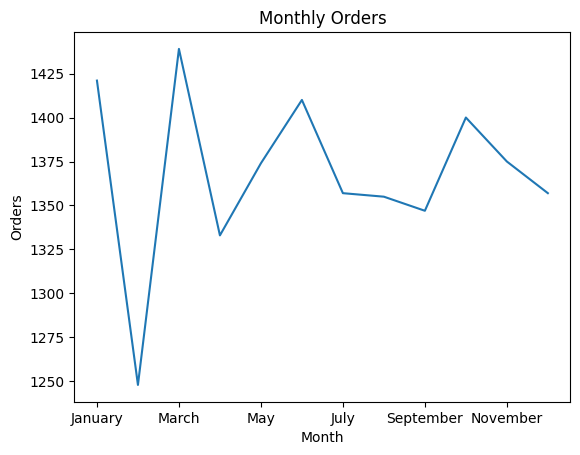

In [ ]:
Revenue_analysis.groupby('Order_Month')['Order_ID'].nunique().plot(kind="line")
plt.title("Monthly Orders")
plt.xlabel("Month")
plt.ylabel("Orders")
plt.show()

In [ ]:
#Total Revenue and revenue change over time
#The month with the highest revenue is October with over 233,157,000 while
#February has the least sales with 202,195,000.
#Revenue was fluntuating all year round as there was no month with significant peak or fall in sales.
print(Revenue_analysis['Net_Revenue'].sum())
print(Revenue_analysis.groupby('Order_Month')['Net_Revenue'].sum())

2624332151.15
Order_Month
January      2.252820e+08
February     2.025195e+08
March        2.256456e+08
April        2.066860e+08
May          2.246295e+08
June         2.140475e+08
July         2.148270e+08
August       2.136744e+08
September    2.193439e+08
October      2.331570e+08
November     2.265289e+08
December     2.117159e+08
Name: Net_Revenue, dtype: float64


/tmp/ipykernel_648/2384633704.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(Revenue_analysis.groupby('Order_Month')['Net_Revenue'].sum())


/tmp/ipykernel_648/2500198904.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  Revenue_analysis.groupby('Order_Month')['Net_Revenue'].sum().plot(kind="line")


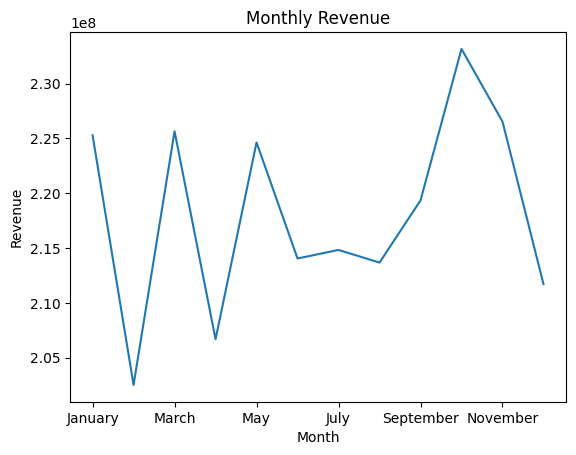

In [ ]:
Revenue_analysis.groupby('Order_Month')['Net_Revenue'].sum().plot(kind="line")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

In [ ]:
Revenue_analysis.groupby('City')['Net_Revenue'].sum().sort_values(ascending=False)

,Net_Revenue
City,
Abuja,2.784438e+08
Benin City,2.728859e+08
Enugu,2.708955e+08
Abeokuta,2.685372e+08
Ibadan,2.631649e+08
Kaduna,2.605984e+08
Port Harcourt,2.594743e+08
Ilorin,2.584785e+08
Kano,2.570465e+08


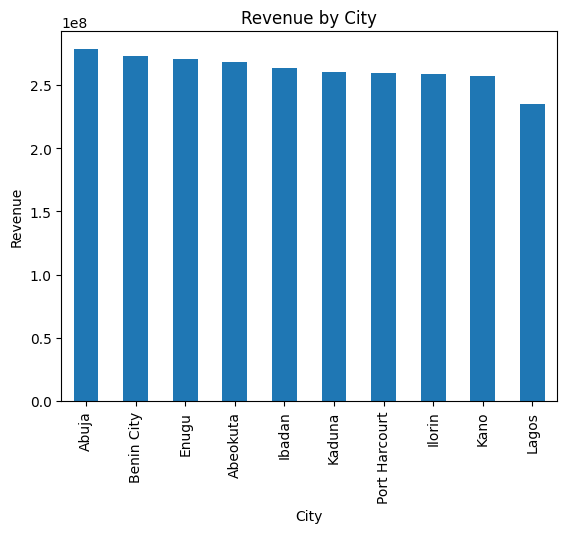

In [ ]:
#Revenue by city
#Abuja recorded the most sales with 10.61% while Lagos has the least with 8.95%
Revenue_analysis.groupby('City')['Net_Revenue'].sum().sort_values(ascending=False).plot(kind="bar")
plt.title("Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue")
plt.show()

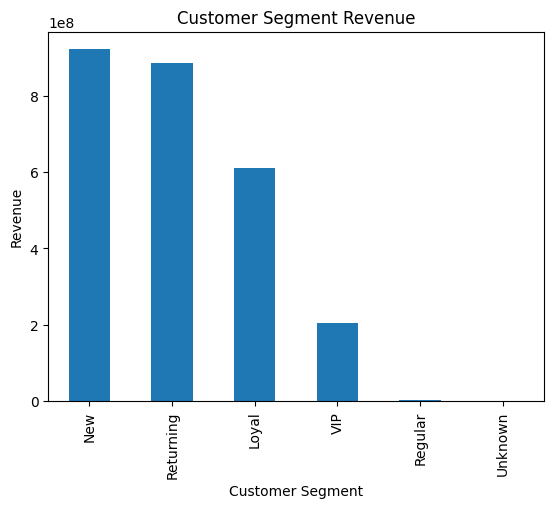

In [ ]:
#Customer Segement with the most revenue
#New customers generated the most revenue while regular customers have the generated the lowest revenue.
#Unknown customer segment has the least but we don't know what category they belong to.
Revenue_analysis.groupby('Customer_Segment')['Net_Revenue'].sum().sort_values(ascending=False).plot(kind='bar')
plt.title("Customer Segment Revenue")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue")
plt.show()

In [ ]:
#Are there periods when order volume increases but revenue does not increase at the same rate?
#As orders counts fluntuates althrough the year with no drastic increase or decrease, it's same with revenue
#However March which recored the highest order do not generate the most revenue.
#Therefore increase in order volume does not necessarily mean increase in revenue.
monthly_summary= Revenue_analysis.groupby('Order_Month').agg(
    Order_Count=('Order_ID', 'nunique'),
    Monthly_Revenue=('Net_Revenue', 'sum')
).reset_index()

print(monthly_summary)


   Order_Month  Order_Count  Monthly_Revenue
0      January         1421     2.252820e+08
1     February         1248     2.025195e+08
2        March         1439     2.256456e+08
3        April         1333     2.066860e+08
4          May         1374     2.246295e+08
5         June         1410     2.140475e+08
6         July         1357     2.148270e+08
7       August         1355     2.136744e+08
8    September         1347     2.193439e+08
9      October         1400     2.331570e+08
10    November         1375     2.265289e+08
11    December         1357     2.117159e+08


/tmp/ipykernel_648/2539375654.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  monthly_summary= Revenue_analysis.groupby('Order_Month').agg(


In [ ]:
#Averge Order Value
AOV = Revenue_analysis['Net_Revenue'].sum() / Revenue_analysis['Order_ID'].nunique()
print(AOV)
print(Revenue_analysis['AOV'].sum())

159475.70194154108
159475.70194154108


In [ ]:
#How do discounts and shipping fees relate to the order amounts, where the relevant fields are available and reliable?
#Relationship between discount and order amount
Revenue_analysis[['Discount', 'Order_ID']].corr()

,Discount,Order_ID
Discount,1.000000,-0.009303
Order_ID,-0.009303,1.000000


In [ ]:
Revenue_analysis['Discount'] = Revenue_analysis['Discount'].replace(99999, 999)
Revenue_analysis['Discount'].unique()


array([   0, 2000, 1000,  500, 3000, 1500, 5000,  999])

In [ ]:
Revenue_analysis['Discount_Range'] = np.where(
    Revenue_analysis['Discount'] <= 0, 'No Discount',
    np.where(Revenue_analysis['Discount'] <= 1000, 'Low',
    np.where(Revenue_analysis['Discount'] <= 3000,'Medium', 'High'))
)

Low discounts has the most orders which indicates that customers are willing to buy more irrespective of how low the discount is, Medium generated the highest discount amount and high with the least order and discount amount signifies that such product are expensive or high value products.

We'll assess the discount if it doesn't affect profit, to see if the business can continue with it since it increase sales, reduce or stop the discount.

In [ ]:
#Relationship between discount and order amount
discount_summary = Revenue_analysis.groupby('Discount_Range').agg(
    Order_Count=('Order_ID', 'nunique'),
    Discount_Amount=('Discount', 'sum')
).reset_index()

print(discount_summary)

  Discount_Range  Order_Count  Discount_Amount
0           High          592          6135000
1            Low         5484          8966449
2         Medium         5444         23476500
3    No Discount         4936                0


In [ ]:
Revenue_analysis['Shipping_Fee'] = Revenue_analysis['Shipping_Fee'].replace(50000, 5000)
Revenue_analysis['Shipping_Fee'].unique()

array([2000, 2500,    0, 3000, 1500, 1000,  500, 5000])

In [ ]:
Revenue_analysis['Shipping_Range'] = np.where(
    Revenue_analysis['Shipping_Fee'] <= 0, 'No Shipping Fee',
    np.where(Revenue_analysis['Shipping_Fee'] <= 1500, 'Low',
    np.where(Revenue_analysis['Shipping_Fee'] <= 3000,'Medium', 'High'))
)

Low shipping has the highest order which indicated that customers are responsive to affordable shipping, while medium generated the most revenue which signifies that customers are willing to pay a bit more when necessary lastly the high shipping fee discourages customers from purchasing. Therefore the high shipping fee should be eliminated or restrategized in order not to be a barrier.

In [ ]:
#Relationship between shipping fee and order amount
Shipping_summary = Revenue_analysis.groupby('Shipping_Range').agg(
    Order_Count=('Order_ID', 'nunique'),
    Shipping_Amount=('Shipping_Fee', 'sum')
).reset_index()

print(Shipping_summary)

    Shipping_Range  Order_Count  Shipping_Amount
0             High           14           110000
1              Low         7492         20140500
2           Medium         6496         31914500
3  No Shipping Fee         2454                0


In [ ]:
Revenue_analysis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34795 entries, 0 to 34794
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Customer_ID           34795 non-null  int64         
 1   Customer_Name         34795 non-null  object        
 2   Age                   34795 non-null  int64         
 3   Gender                34795 non-null  object        
 4   City                  34795 non-null  object        
 5   State                 34795 non-null  object        
 6   Phone                 34718 non-null  object        
 7   Acquisition_Channel   34795 non-null  object        
 8   Customer_Segment      34795 non-null  object        
 9   Signup_Date           34795 non-null  datetime64[ns]
 10  Order_ID              34795 non-null  int64         
 11  Order_Date            34721 non-null  datetime64[ns]
 12  Order_Status          34795 non-null  object        
 13  Payment_Method  

In [ ]:
Revenue_analysis.head()

,Customer_ID,Customer_Name,Age,Gender,City,State,Phone,Acquisition_Channel,Customer_Segment,Signup_Date,...,Order_Year,Line_Total,Order_count,Net_Revenue,Customer_Revenue,Days_since_signup,Order_Value_Category,AOV,Discount_Range,Shipping_Range
0,100001,Daniel Thomas,34,Female,Kaduna,Kaduna,+2348030853448,Google,Returning,2023-04-28,...,2025.0,20218.20,1,18218.20,232995.98,643.0,Low,1.107086,No Discount,Medium
1,100001,Daniel Thomas,34,Female,Kaduna,Kaduna,+2348030853448,Google,Returning,2023-04-28,...,2025.0,216777.78,1,214777.78,232995.98,643.0,Low,13.051640,No Discount,Medium
2,100002,John Musa,28,Male,Ilorin,Kwara,+2348041279947,Facebook,Returning,2024-06-30,...,2025.0,160250.64,4,155750.64,479318.86,534.0,Low,9.464672,Medium,Medium
3,100002,John Musa,28,Male,Ilorin,Kwara,+2348041279947,Facebook,Returning,2024-06-30,...,2025.0,16093.01,4,11593.01,479318.86,534.0,Low,0.704485,Medium,Medium
4,100002,John Musa,28,Male,Ilorin,Kwara,+2348041279947,Facebook,Returning,2024-06-30,...,2025.0,69926.98,4,65426.98,479318.86,534.0,Low,3.975874,Medium,Medium


#Product Analysis

In [ ]:
Product_p.head()

,Product_ID,Product_Name,Category,Unit_Price_x,Cost_Price,Supplier,Stock_Level,Order_Item_ID,Order_ID,Quantity,...,Payment_Method,Shipping_City,Shipping_Fee,Discount,Product_Revenue,Net_Revenue,Product_Cost,Profit,Profit_Margin,Stock_Status
0,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800166,500286,4.0,...,Bank Transfer,Ilorin,2500,1500,37892.96,33892.96,32209.016,1683.944,4.443949,High
1,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800199,507343,5.0,...,Cash on Delivery,Lagos,2000,0,47366.20,45366.20,40261.270,5104.930,10.777580,High
2,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800231,509760,2.0,...,Card,Enugu,1500,2000,18946.48,15446.48,16104.508,-658.028,-3.473088,High
3,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800261,515493,2.0,...,Card,Enugu,1500,0,18946.48,17446.48,16104.508,1341.972,7.082962,High
4,2001,Brightening Moisturizer 1,Skincare,9473.24,8052.254,PureCare,384,800390,502127,3.0,...,Card,Abeokuta,1500,0,28419.72,26919.72,24156.762,2762.958,9.721975,High


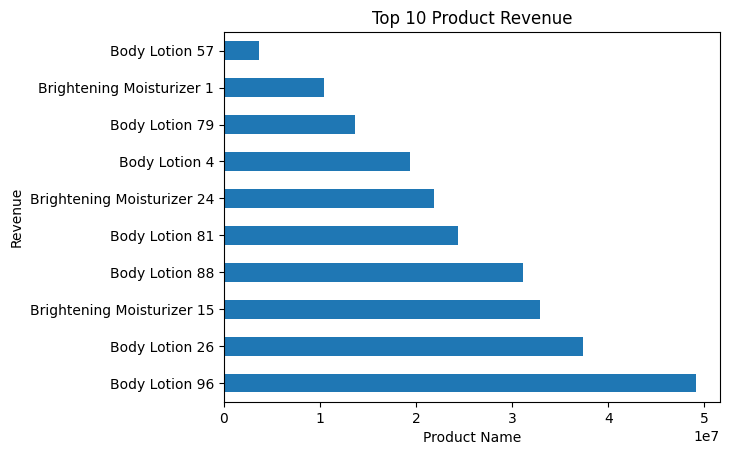

In [ ]:
#Product with the highest and lowest revenue
#Vitamin C Serum is the product with the highest revenue with 63,200,518 in sales
#while Gentle Cleanser 86 generated the least revenue with 2,967,526
Product_p.groupby('Product_Name')['Net_Revenue'].sum().head(10).sort_values(ascending=False).plot(kind='barh')
plt.title("Top 10 Product Revenue")
plt.xlabel("Product Name")
plt.ylabel("Revenue")
plt.show()


In [ ]:
Product_p['Quantity'].sum()

np.float64(121369.0)

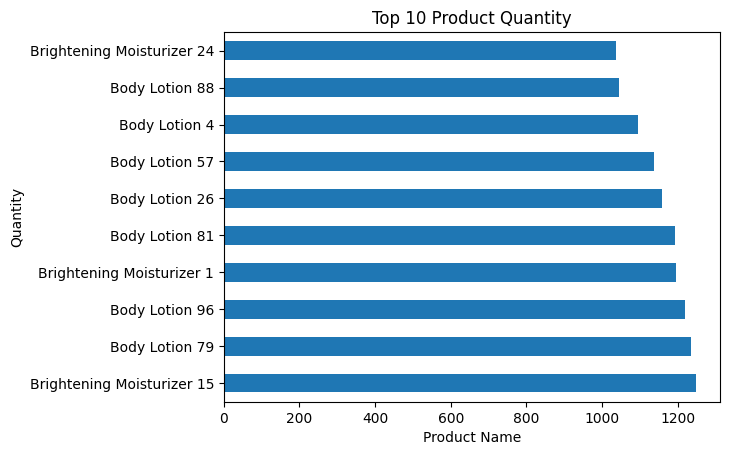

In [ ]:
#Products with the highest and least units
#With a total of 121369 units sold, Brightening Moisturizer 78 sold the most unit with 1423 while
#Brightening Moisturizer 24 has the fewest quantity sold with 1046 units.
Product_p.groupby('Product_Name')['Quantity'].sum().head(10).sort_values(ascending=False).plot(kind='barh')
plt.title("Top 10 Product Quantity")
plt.xlabel("Product Name")
plt.ylabel("Quantity")
plt.show()

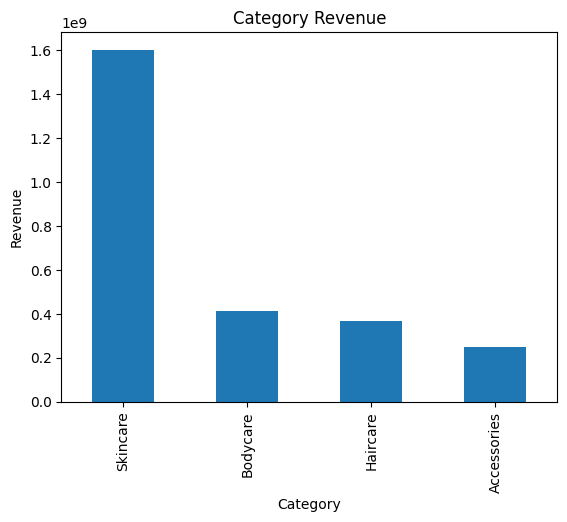

In [ ]:
#Which product categories contribute the most to total revenue?
#Skincare contributes the highest revenue while accessories have the least
Product_p.groupby('Category')['Net_Revenue'].sum().sort_values(ascending=False).plot(kind='bar')
plt.title("Category Revenue")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.show()

In [ ]:
#Are the best selling product also the high revenue product
product_summary = Product_p.groupby('Product_Name').agg(
    Order_Count=('Order_ID', 'nunique'),
    Revenue=('Net_Revenue', 'sum')
).reset_index()

product_summary = product_summary.sort_values(by='Order_Count', ascending=False)

print(product_summary)

                  Product_Name  Order_Count      Revenue
98          Vitamin C Serum 85          406  63200518.50
20           Clay Face Mask 99          381  40293508.24
67        Niacinamide Serum 17          381  23954090.28
13  Brightening Moisturizer 78          379   6588947.75
94          Vitamin C Serum 62          379  17065948.25
..                         ...          ...          ...
27      Exfoliating  Toner  43          316  31557479.54
9   Brightening Moisturizer 24          315  21899847.73
30        Exfoliating Toner 66          310  37206571.70
72        Niacinamide Serum 64          308  16499171.77
5               Body Lotion 88          305  31129631.40

[100 rows x 3 columns]


/tmp/ipykernel_648/1068968869.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  Revenue_analysis.groupby('Order_Month')['Order_ID'].nunique().plot(kind='line')


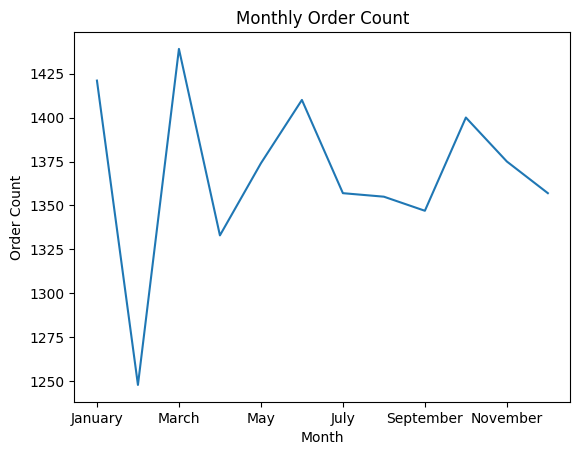

In [ ]:
#Product sales trend over time
#There was a peak sales in March
Revenue_analysis.groupby('Order_Month')['Order_ID'].nunique().plot(kind='line')
plt.title("Monthly Order Count")
plt.xlabel("Month")
plt.ylabel("Order Count")
plt.show()


Text(0.5, 0, 'Product Name')

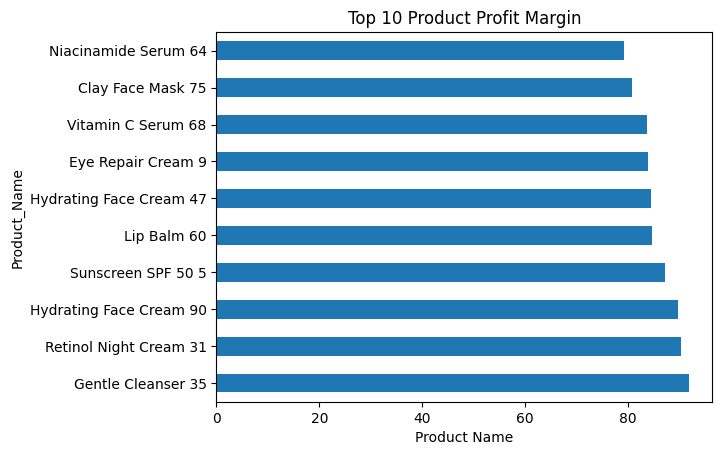

In [ ]:
#Profit Margin for each product
#Gentle cleanser 35 has the highest profit margin with 91.8%
Product_p.groupby('Product_Name')['Profit_Margin'].mean().sort_values(ascending=False).head(10).plot(kind='barh')
plt.title("Top 10 Product Profit Margin")
plt.xlabel("Product Name")

In [ ]:
Product_p.groupby('Product_Name')['Profit_Margin'].mean().sort_values(ascending=False)

,Profit_Margin
Product_Name,
Gentle Cleanser 35,91.819254
Retinol Night Cream 31,90.373441
Hydrating Face Cream 90,89.795100
Sunscreen SPF 50 5,87.154744
Lip Balm 60,84.696430
...,...
Niacinamide Serum 82,-inf
Tea Tree Gel 12,-inf
Tea Tree Gel 84,-inf


In [ ]:
Product_p.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34870 entries, 0 to 34869
Data columns (total 25 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Product_ID       34870 non-null  int64         
 1   Product_Name     34870 non-null  object        
 2   Category         34870 non-null  object        
 3   Unit_Price_x     34870 non-null  float64       
 4   Cost_Price       34870 non-null  float64       
 5   Supplier         34870 non-null  object        
 6   Stock_Level      34870 non-null  int64         
 7   Order_Item_ID    34870 non-null  int64         
 8   Order_ID         34870 non-null  int64         
 9   Quantity         34820 non-null  float64       
 10  Unit_Price_y     34870 non-null  float64       
 11  Line_Total       34820 non-null  float64       
 12  Customer_ID      34870 non-null  int64         
 13  Order_Date       34797 non-null  datetime64[ns]
 14  Order_Status     34870 non-null  objec

#Payment Analysis

In [ ]:
Payment_p.head()

,Payment_ID,Order_ID,Payment_Date,Amount_Paid,Payment_Status,Customer_ID,Order_Date,Order_Status,Payment_Method,Shipping_City,Shipping_Fee,Discount,Year,MonthNo,Month_Name,Delay_days
0,900001,509845,2024-03-24,105081.47,Pending,103003,2025-04-30,Delivered,Card,Port Harcourt,2000,1000,2024,3,March,402 days
1,900002,500997,2025-07-30,76221.43,Successful,102432,2024-07-06,Delivered,Card,Ibadan,1000,3000,2025,7,July,-389 days
2,900003,509891,2025-01-04,7808.08,Successful,101712,2024-12-09,Delivered,Card,Enugu,1500,5000,2025,1,January,-26 days
3,900004,510468,2025-10-06,132361.31,Successful,100151,2024-11-20,Delivered,Bank Transfer,Port Harcourt,1500,1000,2025,10,October,-320 days
4,900005,515134,2025-01-09,44998.50,Successful,104840,2025-04-26,Delivered,Bank Transfer,Ibadan,3000,3000,2025,1,January,107 days


In [ ]:
#What percentage of payment was successful?
#About 72.3% of payment was successful while 10.3% still peding as at time of the analysis,
#7.30% were refunded and 9.96% of failed transaction was recorded.
#I recommend they look into the transactions that were refunded and failed to find out the reasom why and what happened.
count = Payment_p.groupby('Payment_Status')['Order_ID'].nunique()
percent = (count/count.sum())*100
print(percent)

Payment_Status
Failed         9.965417
Pending       10.332416
Refunded       7.304679
Successful    72.333969
Unknown        0.063519
Name: Order_ID, dtype: float64


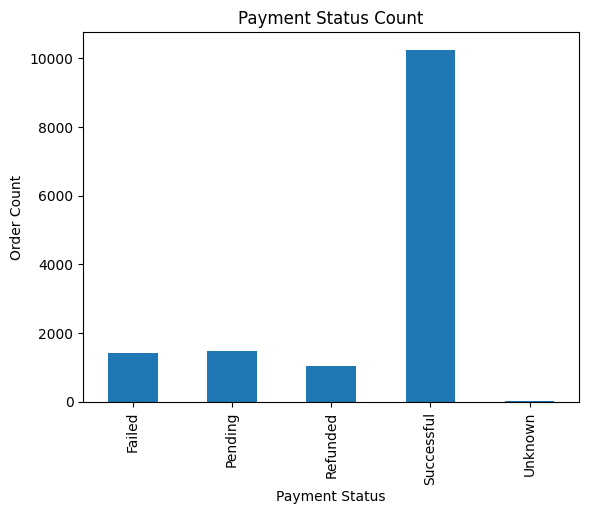

In [ ]:
#Count by payment status
Payment_p.groupby('Payment_Status')['Order_ID'].nunique().plot(kind='bar')
plt.title("Payment Status Count")
plt.xlabel("Payment Status")
plt.ylabel("Order Count")
plt.show()

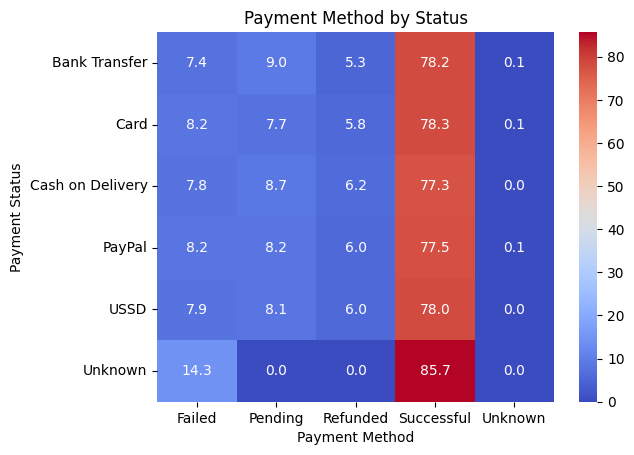

In [ ]:
#Payment method with the highest failed transaction
#Card has the record with the highest failed transaction with 8.19% if its total transaction.
#Bank tranfer has the least with 7.4% of its total transaction failed.
transaction = pd.crosstab(Payment_p['Payment_Method'], Payment_p['Payment_Status'], normalize='index')*100
sns.heatmap(transaction, annot=True, fmt='.1f', cmap='coolwarm')
plt.title("Payment Method by Status")
plt.xlabel("Payment Method")
plt.ylabel("Payment Status")
plt.show()

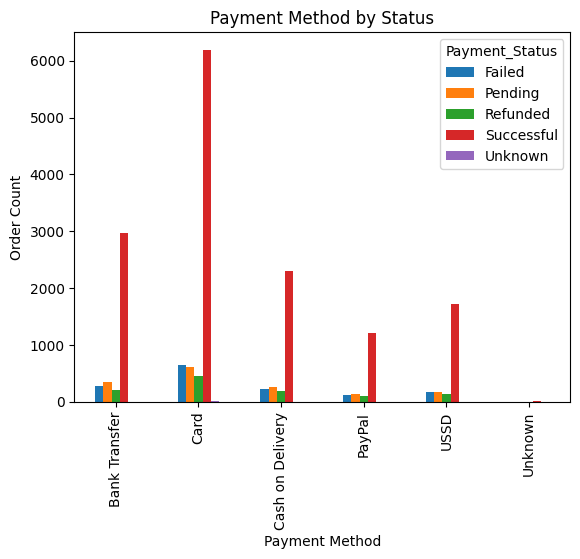

In [ ]:
#Payment method with the highest failed transaction
pd.crosstab(Payment_p['Payment_Method'], Payment_p['Payment_Status']).plot(kind='bar')
plt.title("Payment Method by Status")
plt.xlabel("Payment Method")
plt.ylabel("Order Count")
plt.show()

In [ ]:
#No payment that require investigation other than the unknown section where there
#the data did not include the payment status.
Payment_p.groupby('Payment_Status')['Amount_Paid'].sum()

,Amount_Paid
Payment_Status,
Failed,1.348830e+08
Pending,1.397273e+08
Refunded,9.751326e+07
Successful,1.317527e+09
Unknown,1.116079e+06


In [ ]:
#Transaction volume by status
Payment_p.groupby('Payment_Status')['Payment_ID'].count()

,Payment_ID
Payment_Status,
Failed,1462
Pending,1517
Refunded,1064
Successful,14388
Unknown,9


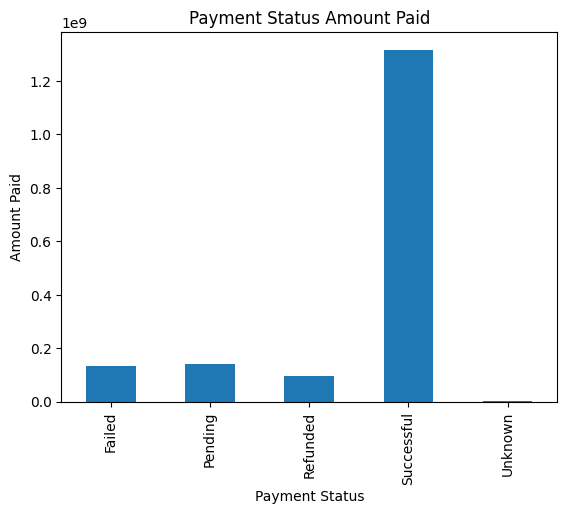

In [ ]:
#How much money is associated with the payment status.
Payment_p.groupby('Payment_Status')['Amount_Paid'].sum().plot(kind='bar')
plt.title("Payment Status Amount Paid")
plt.xlabel("Payment Status")
plt.ylabel("Amount Paid")
plt.show()

In [ ]:
#Sorting month name in order
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

Payment_p['Month_Name'] = pd.Categorical(
    Payment_p['Month_Name'],
    categories=month_order,
    ordered=True
)

/tmp/ipykernel_648/4138088695.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  Payment_p.groupby('Month_Name')['Amount_Paid'].sum().plot(kind='line')


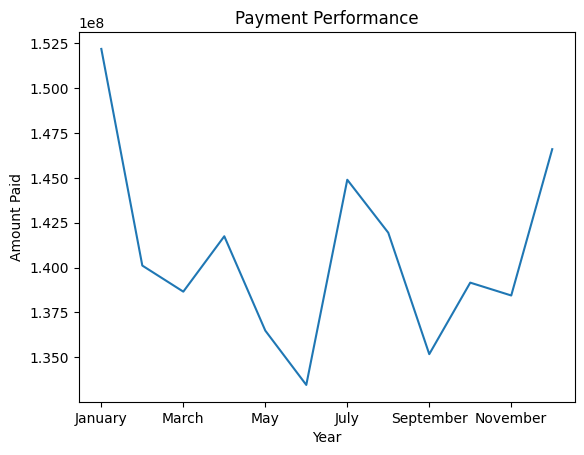

In [ ]:
#Payment performance change over time
Payment_p.groupby('Month_Name')['Amount_Paid'].sum().plot(kind='line')
plt.title("Payment Performance")
plt.xlabel("Year")
plt.ylabel("Amount Paid")
plt.show()

In [ ]:
Payment_p.groupby('Month_Name')['Amount_Paid'].sum()

/tmp/ipykernel_648/309193198.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  Payment_p.groupby('Month_Name')['Amount_Paid'].sum()


,Amount_Paid
Month_Name,
January,1.521888e+08
February,1.401141e+08
March,1.386611e+08
April,1.417477e+08
May,1.364903e+08
June,1.334625e+08
July,1.448976e+08
August,1.419455e+08
September,1.351776e+08


<Axes: xlabel='Year'>

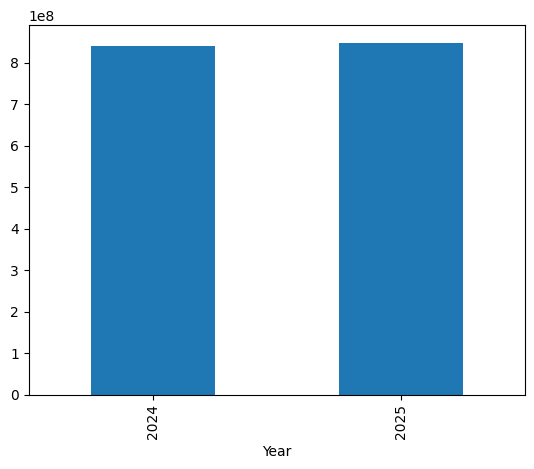

In [ ]:
Payment_p.groupby('Year')['Amount_Paid'].sum().plot(kind='bar')

In [ ]:
#Are there orders whose payment status appears inconsistent with the corresponding order status
#There are 1405 rows whose order status cancelled while payment indicted successful, that need to be investigated.
# Define the logical inconsistencies
# 1. Goods sent but no money received
shipped_but_unpaid = Payment_p["Order_Status"].isin(['Delivered' 'Returned' 'Processing' 'Cancelled']) & Payment_p["Payment_Status"].isin(['Pending' 'Successful' 'Refunded' 'Failed' 'Unknown'])

# 2. Order cancelled but money kept
cancelled_but_paid = (Payment_p["Order_Status"] == "Cancelled") & (Payment_p["Payment_Status"] == "Successful")

# Combine conflicts into a single dataframe
inconsistent_orders = Payment_p[shipped_but_unpaid | cancelled_but_paid]

# Display the problematic rows
print(f"Found {len(inconsistent_orders)} inconsistent orders:")
print(inconsistent_orders[["Order_ID", "Order_Status", "Payment_Status", "Amount_Paid"]])


Found 1405 inconsistent orders:
       Order_ID Order_Status Payment_Status  Amount_Paid
11       514540    Cancelled     Successful    139879.66
14       500044    Cancelled     Successful    106295.10
22       506376    Cancelled     Successful    142223.31
29       504169    Cancelled     Successful     19254.87
61       506560    Cancelled     Successful     91194.29
...         ...          ...            ...          ...
18357    519607    Cancelled     Successful     27642.49
18370    508031    Cancelled     Successful     53722.49
18375    516523    Cancelled     Successful    122655.26
18398    507339    Cancelled     Successful    121057.68
18399    500993    Cancelled     Successful     52086.80

[1405 rows x 4 columns]


In [ ]:
Payment_p.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18440 entries, 0 to 18439
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype          
---  ------          --------------  -----          
 0   Payment_ID      18440 non-null  int64          
 1   Order_ID        18440 non-null  int64          
 2   Payment_Date    18417 non-null  datetime64[ns] 
 3   Amount_Paid     18410 non-null  float64        
 4   Payment_Status  18440 non-null  object         
 5   Customer_ID     18440 non-null  int64          
 6   Order_Date      18396 non-null  datetime64[ns] 
 7   Order_Status    18440 non-null  object         
 8   Payment_Method  18440 non-null  object         
 9   Shipping_City   18440 non-null  object         
 10  Shipping_Fee    18440 non-null  int64          
 11  Discount        18440 non-null  int64          
 12  Year            18417 non-null  Int64          
 13  MonthNo         18417 non-null  Int64          
 14  Month_Name      18417 non-null  catego

#Return Analysis

In [ ]:
Return_p.head()

,Return_ID,Order_ID,Return_Date,Return_Reason,Refund_Amount,Return_Status,Customer_ID,Order_Date,Order_Status,Payment_Method,Shipping_City,Shipping_Fee,Discount,Return_MonthNo,Return_Month,Return_Year,Processing_days
0,700001,508704,2025-12-11,Late Delivery,48990.91,Approved,100592,2025-08-12,Delivered,USSD,Abuja,3000,500,12.0,December,2025.0,121 days
1,700002,512276,2024-09-22,Quality Issue,13818.60,Approved,100743,2024-10-30,Delivered,Card,Abuja,2500,0,9.0,September,2024.0,-38 days
2,700003,517912,2024-10-28,Damaged,23601.06,Approved,102812,2025-06-29,Delivered,Bank Transfer,Kano,2500,0,10.0,October,2024.0,-244 days
3,700004,516823,2025-04-19,Damaged,98853.93,Approved,103623,2025-12-05,Returned,Card,Benin City,0,1000,4.0,April,2025.0,-230 days
4,700005,513212,2025-09-08,Changed Mind,123588.76,Approved,102994,2025-01-25,Delivered,Bank Transfer,Port Harcourt,1500,2000,9.0,September,2025.0,226 days


In [ ]:
#Changing return year and nonth number datatype
Return_p['Return_Year'] = Return_p['Return_Year'].astype('Int64')
Return_p['Return_MonthNo'] = Return_p['Return_Year'].astype('Int64')

In [ ]:
#How many orders have return records
Return_p['Order_ID'].nunique()

2318

In [ ]:
#Return rate
#With a total of 15% returns on all orders
Total_Orders = Revenue_analysis['Order_ID'].nunique()
Total_Return = Return_p['Return_ID'].nunique()
Return_rate = (Total_Return / Total_Orders) * 100
print(Return_rate)


15.009722897423433


In [ ]:
Return_p['Return_Reason'].value_counts()

,count
Return_Reason,
Damaged,455
Other,415
Quality Issue,407
Late Delivery,407
Wrong Item,400
Changed Mind,386


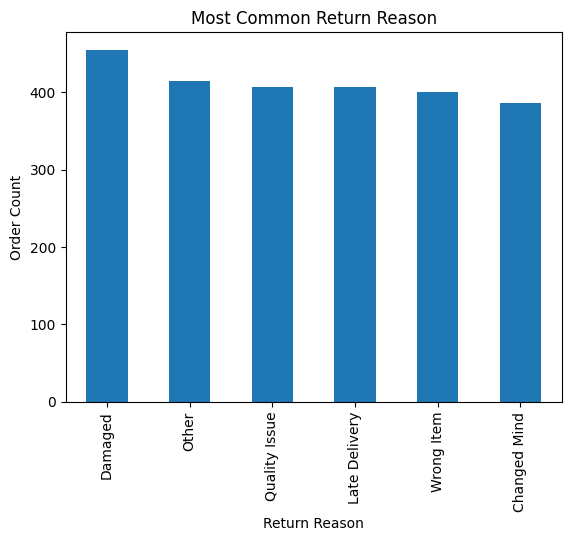

In [ ]:
#Most common return reason
#Damaged products are the highest with 455 returns.
#Damaged products, quality issue, wrong item and late delivery are problems the business can resolve from
#their end while the business have no control over changed mind.
#The business can ensure strict quality control before others are sent out and monitor the delivery to ensure the returns
#on theses products are minimal and not lose money.
Return_p['Return_Reason'].value_counts().head(10).plot(kind='bar')
plt.title("Most Common Return Reason")
plt.xlabel("Return Reason")
plt.ylabel("Order Count")
plt.show()

In [ ]:
#The data indicated that majority of the returns were approved.
pd.crosstab(Return_p['Return_Status'], Return_p['Return_Reason'])

Return_Reason,Changed Mind,Damaged,Late Delivery,Other,Quality Issue,Wrong Item
Return_Status,,,,,,
Approved,280,338,287,299,287,287
Pending,50,44,50,48,48,57
Refund,1,2,1,3,1,1
Rejected,53,69,69,64,70,54
Unknown,2,2,0,1,1,1


In [ ]:
#How much revenue is associated with returned items
Return_p['Refund_Amount'].sum()

np.float64(198629286.41)

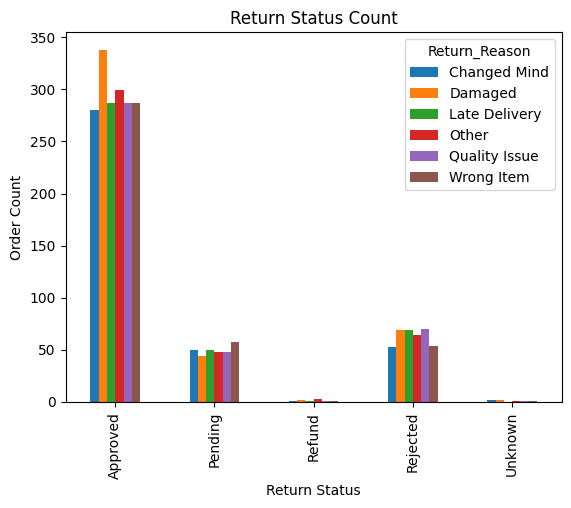

In [ ]:
#How many returns are approved, rejected or pending
pd.crosstab(Return_p['Return_Status'], Return_p['Return_Reason']).plot(kind='bar')
plt.title("Return Status Count")
plt.xlabel("Return Status")
plt.ylabel("Order Count")
plt.show()

In [ ]:
#Return trend per month
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

Return_p['Return_Month'] = pd.Categorical(
    Return_p['Return_Month'],
    categories=month_order,
    ordered=True
)



In [ ]:
Return_p.groupby('Return_Month')['Return_ID'].nunique()

/tmp/ipykernel_648/236886978.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  Return_p.groupby('Return_Month')['Return_ID'].nunique()


,Return_ID
Return_Month,
January,210
February,178
March,218
April,201
May,210
June,196
July,206
August,223
September,207


/tmp/ipykernel_648/3066181515.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  Return_p.groupby('Return_Month')['Return_ID'].nunique().plot(kind='line')


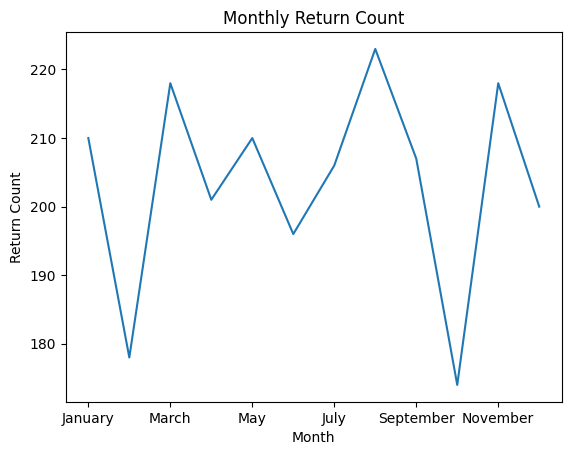

In [ ]:
#August has the highest returns with 223 while February has the least with 178 returns.
Return_p.groupby('Return_Month')['Return_ID'].nunique().plot(kind='line')
plt.title("Monthly Return Count")
plt.xlabel("Month")
plt.ylabel("Return Count")
plt.show()

In [ ]:

Return_p['Processing_days'] = Return_p['Return_Date'] - Return_p['Order_Date']


In [ ]:
abnormal = Return_p['Processing_days'] < '0 days'
print(abnormal.sum())

1198


In [ ]:
#Repalcing the negative days with 0:
zero_days = pd.Timedelta(0, unit='D')
Return_p['Processing_days'] = Return_p['Processing_days'].clip(lower=zero_days)


In [ ]:
#How long does it take customers to return products after ordering them
#(Average return days)
Return_p['Processing_days'].mean()

Timedelta('125 days 03:41:40.492610838')

In [ ]:
Return_p.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2470 entries, 0 to 2469
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype          
---  ------           --------------  -----          
 0   Return_ID        2470 non-null   int64          
 1   Order_ID         2470 non-null   int64          
 2   Return_Date      2441 non-null   datetime64[ns] 
 3   Return_Reason    2470 non-null   object         
 4   Refund_Amount    2470 non-null   float64        
 5   Return_Status    2470 non-null   object         
 6   Customer_ID      2470 non-null   int64          
 7   Order_Date       2465 non-null   datetime64[ns] 
 8   Order_Status     2470 non-null   object         
 9   Payment_Method   2470 non-null   object         
 10  Shipping_City    2470 non-null   object         
 11  Shipping_Fee     2470 non-null   int64          
 12  Discount         2470 non-null   int64          
 13  Return_MonthNo   2441 non-null   Int64          
 14  Return_Month     2441 no

In [ ]:
Returns = Return_p.merge(order_items, on='Order_ID', how='left')

In [ ]:
Items = Returns.merge(products, on='Product_ID', how='left')

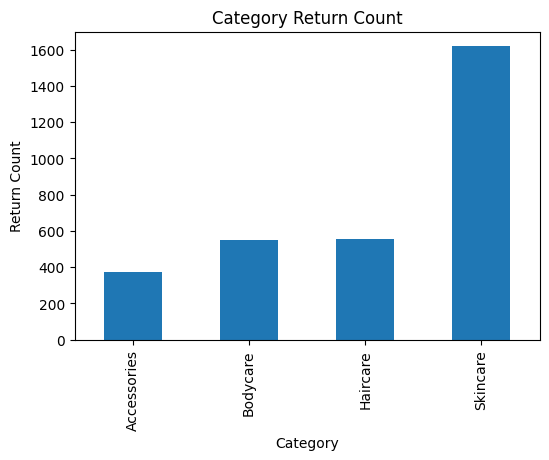

In [ ]:
plt.figure(figsize=(6, 4))
Items.groupby('Category')['Return_ID'].nunique().plot(kind='bar')
plt.title("Category Return Count")
plt.xlabel("Category")
plt.ylabel("Return Count")
plt.show()

In [ ]:
Items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4715 entries, 0 to 4714
Data columns (total 28 columns):
 #   Column           Non-Null Count  Dtype          
---  ------           --------------  -----          
 0   Return_ID        4715 non-null   int64          
 1   Order_ID         4715 non-null   int64          
 2   Return_Date      4663 non-null   datetime64[ns] 
 3   Return_Reason    4715 non-null   object         
 4   Refund_Amount    4715 non-null   float64        
 5   Return_Status    4715 non-null   object         
 6   Customer_ID      4715 non-null   int64          
 7   Order_Date       4709 non-null   datetime64[ns] 
 8   Order_Status     4715 non-null   object         
 9   Payment_Method   4715 non-null   object         
 10  Shipping_City    4715 non-null   object         
 11  Shipping_Fee     4715 non-null   int64          
 12  Discount         4715 non-null   int64          
 13  Return_MonthNo   4663 non-null   Int64          
 14  Return_Month     4663 no